# Visión por Computador - Práctica 3 - Extracción (y Emparejamiento) de Características y Registrado de Imágenes

#### 12 puntos   |   Fecha de entrega: 1 de Enero de 2026, 23:59   |   Forma de entrega: a través de la tarea creada en https://pradogrado2526.ugr.es/

### Estudiante: Jose María Martín Martín



## Normas de desarrollo y entrega de la práctica

1. Para este trabajo, al igual que para los demás, se debe presentar código, resultados, discusión de los mismos, y presentación y análisis del trabajo realizado, todo integrado en el propio Google Colab Notebook (es decir, no se entrega ninguna memoria separada en `.pdf` ni ningún código `.py`). Se recuerda que código y resultados sin informe explicativo no puntúa. Resulta también fundamental recordar que solo se acepta la entrega de ficheros `.ipynb` (no resulta válido entregar un fichero `.py`).

2. En relación con el punto anterior, se recuerda que se proporciona un Notebook, denominado `Ejemplo_Otsu.ipynb`, que muestra un ejemplo de respuesta y solución a un potencial ejercicio. El propósito de este Notebook es servir de referencia al alumnado acerca de cómo responder los ejercicios planteados. Véase que, por ejemplo, en aras de diferenciar con facilidad enunciados y respuestas, estas últimas se presentan en otro color (azul, en ese caso).

3. El diseño de celdas del documento debe ser respetado. Es decir, no se puede modificar el orden de los ejercicios o alterar la estructura del Notebook, de forma que dificulte localizar los contenidos. Aunque sí se puede, por ejemplo, crear nuevas subsecciones dentro de las secciones ya existentes para estructurar y organizar con más claridad las respuestas, así como para incluir los experimentos extra que se deseen.

4. Tal y como se muestra en `Ejemplo_Otsu.ipynb`, no hay ningún problema en emplear técnicas de IA generativa (como ChatGPT o Gemini) para crear el código de los distintos ejercicios o para enriquecer el análisis y descripción del trabajo realizado (aunque, obvia decirlo, su uso no es obligatorio). Pero, en caso de usarse, sí se debe aclarar de qué modo se ha usado la IA, con qué objetivo, y se debe demostrar que se entiende perfectamente lo que se ha hecho.

5. Solo se entregará el fichero `.ipynb` (incorporando código, resultados, y explicación del trabajo realizado y los resultados obtenidos) y no se enviarán las imágenes empleadas. El path para la lectura de imágenes, o cualquier otro fichero de entrada, debe ser siempre “/content/drive/My Drive/images/nombre_fichero”.

6. El código deberá  presentarse adecuadamente comentado y con los resultados obtenidos en cada apartado, junto con la presentación del trabajo realizado y la discusión y análisis de los resultados obtenidos. Es importante reiterar que la entrega de código sin informe explicativo o valoraciones no puntúa. Por otro lado, el código debe ir comentado en comentarios en celdas de código, mientras que el análisis y discusión, tanto del trabajo realizado como de los resultados obtenidos, debe ir en celdas de texto.






### Materiales de Apoyo

En caso de que el alumnado tenga dudas sobre Python, OpenCV o el uso de Google Colab, se recuerda que en PRADO hay materiales de apoyo (https://pradogrado2526.ugr.es/mod/folder/view.php?id=95307):
-  Introducción a Python: https://pradogrado2526.ugr.es/pluginfile.php/243163/mod_folder/content/0/1.%20Introduccion%20a%20Python.pdf
- Introducción a NumPy, Matplotlib y Scikit-learn: https://pradogrado2526.ugr.es/pluginfile.php/243163/mod_folder/content/0/2.%20Introducción%20a%20Numpy%20Matplotlib%20y%20sklearn.pdf
- Notebook con toda la información anterior (y más cosas): https://pradogrado2526.ugr.es/pluginfile.php/243163/mod_folder/content/0/Guia_Python.ipynb
- Ejercicios y ejemplos de repaso: https://pradogrado2526.ugr.es/pluginfile.php/243163/mod_folder/content/0/3.%20Ejercicios%20y%20ejemplos%20de%20repaso.pdf
- Fundamentos de Python para lectura, visualización y manipulación de imágenes: https://pradogrado2526.ugr.es/pluginfile.php/243163/mod_folder/content/0/4.%20Fundamentos%20de%20Python%20para%20manipulacion%20de%20imagenes.pdf (y Notebook asociado: https://pradogrado2526.ugr.es/pluginfile.php/243163/mod_folder/content/0/Guia_fundamentos_imagenes.ipynb)
- Ideas sobre cómo redactar un documento académico-científico (útil para saber cómo documentar las respuestas a los ejercicios, el Notebook en su conjunto, y la memoria del proyecto final o de un TFG/TFM): https://pradogrado2526.ugr.es/pluginfile.php/243163/mod_folder/content/0/Algunas%20ideas%20sobre%20cómo%20elaborar%20un%20informe%20académico-científico.pdf
- Ejemplo de respuesta a un hipotético ejercicio sobre el algoritmo de umbralización de Otsu: https://pradogrado2526.ugr.es/pluginfile.php/243164/mod_folder/content/0/Ejemplo_Otsu.ipynb

<font color='blue'>En esta práctica aprenderás:

<font color='blue'>a) A detectar puntos de interés utilizando el detector de esquinas de Harris (Ejercicio 1).

<font color='blue'>b) A encontrar correspondencias entre los _keypoints_ (puntos de interés) de dos imágenes utilizando distintos descriptores (Ejercicio 2).

<font color='blue'>c) A componer un mosaico/panorama a partir de un conjunto de imágenes utilizando homografías (Ejercicio 3).

In [ ]:
# Let's start importing all background modules
# We start by getting access to the drive
from google.colab import drive
drive.mount('/content/drive', force_remount=True)
import sys,os
# change directory
%cd '/content/drive/My Drive'
# Let's import the python module exercises.py  to have access to its functions and Classes
get_image = lambda route: os.path.join('/content/drive/MyDrive/images/', route)
get_imageSN = lambda route: os.path.join('/content/drive/MyDrive/panoramas/Small_1029_SierraNevada/', route)
import numpy as np
from matplotlib import pyplot as plt
import cv2

Mounted at /content/drive
/content/drive/My Drive


In [ ]:
'''
This function receives a string with the filename of the image to read,
and a flag indicating if we want to read it in color/RGB (flagColor=1) or gray level (flagColor=0)

Example of use:
im1=readIm(get_image('apple.jpg'),0)

'''
def readIm(filename, flagColor=1):
  # cv2 reads BGR format
  im=cv2.imread(filename)
  # change to  RGB and return the image
  if(flagColor):
    return cv2.cvtColor(im, cv2.COLOR_BGR2RGB)
  # change from BGR to grayscale instead if flag is 0
  return cv2.cvtColor(im, cv2.COLOR_BGR2GRAY)

In [ ]:
'''
This function receives an array of arbitrary real numbers (that could include even negative values),
and returns an 'image' in the range [0,1].
flag_GLOBAL allows the user to normalize the whole image (including all channels) or to normalize
each channel/band independently.
'''
def rangeDisplay01(im, flag_GLOBAL= True):
  im = im.astype(float)
  if flag_GLOBAL:
    im = (im - im.min())/(im.max() - im.min())
  else:
    # bands normalization
    for band in range(im.shape[2]):
      im[:, :, band] = (im[:, :, band] - im[:, :, band].min())/(im[:, :, band].max() - im[:, :, band].min())
      # Note: remember that, for plt.imshow with RGB data, the valid range is [0..1] for floats and [0..255] for integers.
  return im

In [ ]:
'''
This function displays a single image, including a title, using a magnification factor.

Example of use:
im1=readIm(get_image('apple.jpg'),0)
displayIm(im1,'Manzana',0.5)

'''
def displayIm(im, title='Result',factor= 2):
  # First normalize range
  max=np.max(im)
  min=np.min(im)
  if min<0 or max>255:
    im=rangeDisplay01(im,flag_GLOBAL=True)
  if len(im.shape) == 3:
    # im es tribanda
    plt.imshow(im, cmap='jet')
  else:
    # im es monobanda
    plt.imshow(im, cmap='gray')
  figure_size = plt.gcf().get_size_inches()
  plt.gcf().set_size_inches(factor * figure_size)
  plt.title(title)
  plt.xticks([]), plt.yticks([]) # eliminamos numeración
  plt.show()

In [ ]:
'''
This function displays multiple images (including a title and using a magnification factor)
of equal size. The input to the function is a list of images.

Example of use:
im1=readIm(get_image('apple.jpg'),1)
images = [im1,im1,im1]

displayMI_ES(images, title='Manzanas',factor=1)

'''
def displayMI_ES(vim, title='Result',factor=2):
  # We set the maximun number of images to concatenate by columns
  maxcolumns=3
  # number of images to display
  numberim=len(vim)
  # The simplest case, one row: the maximum number of columns is larger than the images to stack
  # This is, by default, we put together the images column-wise
  if len(vim) < maxcolumns:
    out=vim[0]
    for item in range(1,len(vim)):
      #displayIm(out,str(item),1)
      out=np.hstack((out,vim[item]))

  # Else, if maxcolumns is smaller or equal than the number of images to stack
  else:
    # We check if all rows and columns are going to be 'busy', or if otherwise we need an extra-row
    if np.mod(len(vim),maxcolumns)== 0:
      maxrows=numberim//maxcolumns
    else:
      maxrows=numberim//maxcolumns+1

    # we build up the first block-row
    out=vim[0]
    for item in range(1,maxcolumns):
      out=np.hstack((out,vim[item]))
    # We build up the rest of block-rows
    for block in range(1,maxrows):
      #print(block)
      row=vim[block*maxcolumns]
      for item in range(1,maxcolumns):
        # We still have images to stack
        if block*maxcolumns+item < numberim:
          row=np.hstack((row,vim[block*maxcolumns+item]))
        # We do not have more images, and we have to fill with black
        else:
          row=np.hstack((row,np.zeros(vim[0].shape,dtype=vim[0].dtype)))
          #print(row.dtype)
          # if we don't include ',dtype=vim[0].dtype', np.zeros will include float
          # numbers in the matrix. This will make that the whole matrix will be
          # considered as floats, and values larger than 1 will be clipped to 1,
          # displaying an almost totally white image
      # add the new block-row
      out=np.vstack((out,row))
  return displayIm(out,title,factor)

In [ ]:
# AQUI SE INCLUYEN LAS FUNCIONES NECESARIAS DE LA PRACTICA 1

# A CUBRIR POR EL ALUMNADO

# Funcion que calcula el valor de K a partir de sigma. Hay que calcular el
# primer valor entero k tal que k >= 3sigma
def GetK(sigma):
  return np.ceil(3*sigma)

def GaussFunc(x,sigma):

    # Se devuelve la función gaussiana e ^ ( -(x^2) / (2 sigma^2))
    return ( np.exp(-(x*x)/(2*sigma*sigma)) )


def GaussDeriv1Func(x,sigma):
    # Se devuelve la primera derivada
    return (-(x)/(sigma*sigma)) * GaussFunc(x,sigma)

def GaussDeriv2Func(x,sigma):
    # Se devuelve la segunda derivada
    return (x*x - sigma*sigma)/(sigma**4) * GaussFunc(x,sigma)

def gaussianMask1D(sigma=0, sizeMask=0, order=0):
    # order = 0 -> función Gaussiana
    # order = 1 -> derivada de la Gaussiana
    # order = 2 -> derivada segunda de la Gaussiana

    # Se calcula o bien sigma a partir de sizeMask o bien sizeMask a partir de
    # sigma. Para ello, dado un valor de sigma, tenemos que buscar el valor k
    # tal que k >= 3sigma y el tamaño de máscara será 2*k + 1.

    # En cambio si tenemos el tamaño de máscara, para calcular sigma tenemos
    # que sizeMask = 2k + 1 => T = 2 * 3sigma + 1 = > sigma = ( T - 1 ) / 6

    # En caso de que ambos valores sean negativos o 0, se toma por defecto
    # sigma = 1 y sizeMask = 7
    if sigma > 0:
      k = GetK(sigma)
      m_size = 2*k + 1
      sig = sigma
    elif sizeMask > 0:
      m_size = sizeMask
      sig = (m_size - 1) / 6
      k = GetK(sig)
    else:
      sig = 1
      k = GetK(sig)
      m_size = 2*k + 1

    # Calculamos el vector de los valores de máscara a evaluar.
    v_mask = np.arange(- k , k +1)

    # Por ultimo aplicamos la función pertinente dependiendo del parámetro order
    if order == 0:

      # En caso de Gaussiana clásica, se normaliza el vector dividiendo por la
      # suma de sus componentes
      mask = GaussFunc(v_mask,sig)
      mask = mask / np.sum(mask)
    elif order == 1:

      # Se normaliza multiplicando por sigma
      mask = sig * GaussDeriv1Func(v_mask,sig)
    elif order == 2:

      # Se normaliza multiplicando por sigma^2
      mask = sig * sig * GaussDeriv2Func(v_mask,sig)

    return mask

# Funcion de la práctica 1 para aplicar convoluciones de orden order
def my2DConv(im, sigma, orders):
  #A CUBRIR POR EL ALUMNADO

  # La estructura de este if ha sido proporcionada por ChatGPT para no repetir
  # código. Comprueba que orders es una lista de longitud 2 y que sus elementos
  # son enteros de 0 a 2.
  if (
    isinstance(orders, (list, tuple)) and
    len(orders) == 2 and
    all(isinstance(o, int) and 0 <= o <= 2 for o in orders)
  ):
    maskX = gaussianMask1D(sigma=sigma, sizeMask=0, order=orders[0])
    maskY = gaussianMask1D(sigma=sigma, sizeMask=0, order=orders[1])
    return cv2.sepFilter2D(im, cv2.CV_64F, maskX, maskY )
  else:
    print('Error en el orden de la derivada')



# <font color='blue'>**Ejercicio 1:** Harris Corner Detector (4 puntos)

<font color='blue'>Implementar la detección de los 475-525 puntos Harris más fuertes en una imagen (es decir, como mínimo, se deben detectar/mostrar 475 puntos de interés y como máximo 525). Los pasos para implementar el detector de esquinas de Harris son los siguientes:

> <font color='blue'>a) Fijar las escalas de diferenciación ($\sigma_D$) e integración ($\sigma_I$) en $3.0$ y $2.0$, respectivamente.

> <font color='blue'>b) Calcular las derivadas de la imagen. Para ello, se valorará positivamente el emplear las funciones creadas por el propio alumnado (en lugar de emplear directamente `cv2.getDerivKernels()`, `cv2.GaussianBlur()`, `cv2.filter2D()` y similares).

> <font color='blue'>c) Calcular los tres términos de la _Second Moment Matrix_ ($SMM$) en cada píxel. Para ello, aplicar convolución con una máscara gaussiana con $\sigma_I$.

> <font color='blue'>d) A partir de la $SMM$, calcular el valor de Harris en cada píxel de la imagen.

> <font color='blue'>e) Aplique la supresión de no máximos mediante la función `corner_peaks()` (https://scikit-image.org/docs/stable/api/skimage.feature.html#skimage.feature.corner_peaks) del módulo `skimage.features`. El alumnado debe seleccionar una `min_distance` adecuada (`The minimal allowed distance separating peaks`) y un umbral de respuesta adecuado en el mapa de Harris para mantener solo la cantidad de _keypoints_ que se solicitan en el enunciado. El resultado será una lista de coordenadas $(x,y)$. Extraiga los valores en estas coordenadas y cree una lista de vectores $(x,y,value)$.

> <font color='blue'>f) Calcule la orientación principal para cada punto. Para ello, primero suavizamos ambas imágenes derivadas con $\sigma=2$ y, a continuación, calculamos la orientación del gradiente en esos puntos.

> <font color='blue'>g) Cree una lista de _keypoints_ usando los puntos seleccionados. Un _keypoint_ suele representarse como un vector que incluye distintos elementos, por ejemplo, $(x,y,scale,orientation)$. En nuestro caso, un _keypoint_ es una estructura de OpenCV (`cv2.KeyPoint`), asociada a cada región detectada, que contendrá las coordenadas $x$ e $y$ del _keypoint_, así como su tamaño ($size$, es decir, el diámetro con el que se va a mostrar) y su orientacion ($angle$, calculada en el paso anterior). El parámetro $size$ de _KeyPoint()_, es decir, el diámetro del _keypoint_ mostrado, debe ser suficientemente grande como para ser visualizado adecuadamente. Una posibilidad es emplear `size=4*np.floor(3*sigmaI)+1`

> <font color='blue'>h) Dibuje los puntos sobre la imagen de entrada usando la función `drawKeyPoints()` (https://docs.opencv.org/4.x/d4/d5d/group__features2d__draw.html#ga5d2bafe8c1c45289bc3403a40fb88920), y los _flags_ `cv2.DRAW_MATCHES_FLAGS_DRAW_OVER_OUTIMG+cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS`.

<font color='blue'>Se deben calcular los puntos de Harris sobre la imagen `Luxemburg_ArcelorMittal_1.JPG`, y se debe mostrar:
* <font color='blue'>El mapa de respuestas de Harris (valor de Harris) en cada píxel de la imagen,
* <font color='blue'>el mapa de Harris umbralizado, es decir, una vez aplicado supresión de no máximos y un umbral mínimo de respuesta adecuado para obtener el número de puntos de interés solicitados,
* <font color='blue'>y la imagen de entrada con los keypoints finales, junto con el número exacto de _keypoints_ detectados (es decir, es necesario hacer un `print()` con el número de puntos de Harris). Para seleccionar el número de esquinas solicitado en el enunciado, el alumnado debe "jugar" con los valores de `min_distance` (en `corner_peaks()`) y el `threshold` que se use sobre las respuestas de Harris. Ambos parámetros se pasan como entrada a la función `NonMaximaSuppression(harrisMap, min_distance, threshold)`, como se ve más abajo.





Vamos a definir las siguientes funciones:
*   **derivatives(im,sigmaD)**: Calcula la derivada en ambos sentidos de una imagen con sigma **sigmaD**. Para esto rescatamos nuestra función **my2DConv** que realiza una convolución de gaussianas y/o derivadas de orden 0,1 o 2.
*   **HarrisMap(dx,dy,sigmaI)**: Calcula el Harris map a partir de la second moment matrix. Esta matriz es:

$$
\mathbf{H}(x,y) =
\begin{pmatrix}
\sum w(x,y)\, I_x^2 & \sum w(x,y)\, I_x I_y \\
\sum w(x,y)\, I_x I_y & \sum w(x,y)\, I_y^2
\end{pmatrix}
=
\begin{pmatrix}
I_x^2 * G_\sigma & I_x I_y * G_\sigma \\
I_x I_y * G_\sigma & I_y^2 * G_\sigma
\end{pmatrix}
$$
      
  Donde $I_x$ representa la derivada de la imagen con respecto a x. y  $G_\sigma$ el filtro de gaussiana de sigmaI. Por último, se calcula el **HarrisMap** de la siguiente forma:
  $$
  Hmap = \frac{Det(H)}{tr(H)}
  $$


In [ ]:


# Esta función calcula las derivadas en X e Y de una imagen.
def derivatives(im,sigmaD):
  # A CUBRIR POR EL ALUMNADO
  # Calculamos las derivadas en cada direccion usando my2DConv
  dx=my2DConv(im, sigmaD, [1,0])
  dy=my2DConv(im, sigmaD, [0,1])
  return dx,dy


# Esta función calcula el mapa de Harris.
# Recibe las derivadas en X e Y, junto con el sigmaI (escala de integración)
# Proporciona como salida una imagen del tamaño de la imagen de entrada, con el
# valor de cornerness (resultado de aplicar el método de Harris) en cada píxel.
def HarrisMap(dx,dy,sigmaI):
  # A CUBRIR POR EL ALUMNADO

  # Calculamos los coeficientes de la matriz H. Para ello
  # hace falta calcular (dx)^2, (dy)^2 y dxdy
  dxx = dx * dx
  dyy = dy * dy
  dxy = dx * dy

  # Convolucionamos estos coeficientes con sigmaI para
  # calcular H
  dxx_sigma_I = my2DConv(dxx, sigmaI, [0,0])
  dyy_sigma_I = my2DConv(dyy, sigmaI, [0,0])
  dxy_sigma_I = my2DConv(dxy, sigmaI, [0,0])

  # Finalmente calculamos el harris map, que es  Det(H) / tr(H)
  HMap = (
          ( dxx_sigma_I * dyy_sigma_I - dxy_sigma_I * dxy_sigma_I )
          / ( dxx_sigma_I + dyy_sigma_I )
        )
  return HMap

Pasamos ahora a definir la **NonMaximaSuppression**. Para ello recibimos como parámetros **harrisMap, min_distance y threshold** y calculamos los corners usando **corner_peaks** de skimage aplicando estos parámetros. El parámetro **min_distance** indica la distancia mínima entre píxeles que pueden ser considerados picos. El parámetro **threshold** se explica más adelante.

In [ ]:
from skimage.feature import corner_peaks
# Función que aplica supresión de no máximos al mapa de Harris obtenido
# tras aplicar HarrisMap().
def NonMaximaSuppression(harrisMap, min_distance, threshold):
  # A CUBRIR POR EL ALUMNADO
  # Sacamos la lista de puntos de corner
  coord = corner_peaks(harrisMap, min_distance=min_distance, threshold_rel=threshold)


  # Calculamos el valor de Harris map en cada pico
  values = [harrisMap[x,y] for x,y in coord]
  return coord, values

Las siguientes funciones calculan la orientación del gradiente de una imagen y crea la lista de keypoints. Para la función de orientación, se realiza un suavizado de cada componente del gradiente y se calcula el **arctan(dy/dx)** en grados. Con respecto a la segunda función, se crea la lista de keypoints a partir de las coordenadas en la imagen, la orientación y la escala.

In [ ]:
# Esta función calcula la orientación del gradiente por píxel en grados.
def orientation(dx,dy):
  # A CUBRIR POR EL ALUMNADO
  # f) Calcular la orientacion
  sigma = 2.0
  dx_smooth = my2DConv(dx, sigma, [0,0])
  dy_smooth = my2DConv(dy, sigma, [0,0])
  theta = np.arctan2(dy_smooth,dx_smooth) * 180 / np.pi
  return theta

# Esta función crea la lista de keypoints a partir de localizaciones, orientaciones y escalas.
def keyPoints(coord,theta,size):
  keyPoints=[]
  for item in coord:
    reg=cv2.KeyPoint(item[1].astype(np.float32), item[0].astype(np.float32), size,
                     theta[item[0],item[1]])
    keyPoints.append(reg)
  return(keyPoints)


Procedemos ahora a leer y mostrar la imagen con la que vamos a trabajar. Para ello leemos su versión en gris y a color. Vamos a usar la imagen en gris para la detección de corners y la imagen a color para la visualización. Se lee la imagen a color sin reescalar al intervalo [0,1] pues por algún motivo en ese caso había problemas para su visualización.

(1440, 1920, 3)


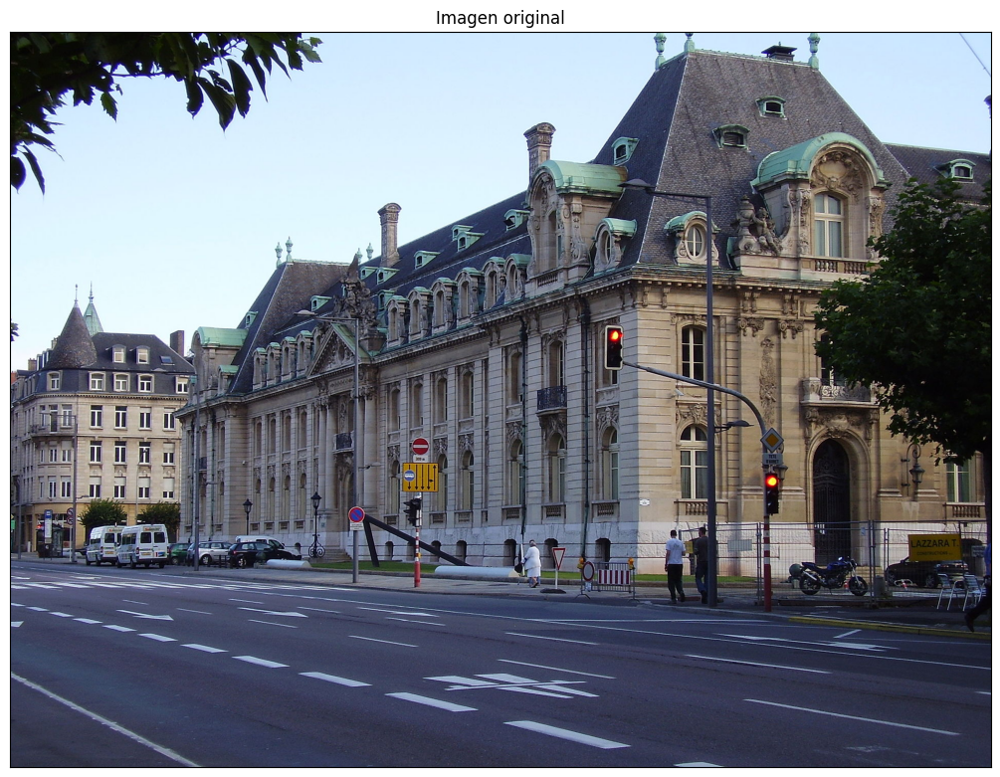

In [ ]:
im = readIm(get_image('Luxemburg_ArcelorMittal_1.JPG'),1)
im_gris = readIm(get_image('Luxemburg_ArcelorMittal_1.JPG'),0).astype(np.float32) / 255.0
print(im.shape)
displayIm(im, 'Imagen original', 2)

Si nos fijamos en la imagen y en el resultado mostrado en la plantilla, podemos comprobar como hay keypoints muy consecutivos, como podemos observar en las hojas del árbol de la esquina superior izquierda. Es por esto que debemos seleccionas un **min_distance** relativamente bajo, por lo que se escogerá el valor 5. Para el valor **threshold_rel** tenemos que tener en cuenta que:
$$
\text{Mantener keypoint si Hmap(keypoint)} \geq \text{threshold_rel x max(Hmap)}
$$

In [ ]:


# a) fijamos sigma de derivacion a 3.0 y de integracion a 2.0
sigmaD=3.0
sigmaI=2.0

# b) Calculo de las derivadas de la imagen

dx, dy = derivatives(im_gris, sigmaD)

# c) y d) Calculo de SMM para Harris map
Hmap = HarrisMap(dx, dy, sigmaI)



Ahora vamos a buscar el valor de **threshold_rel** teniendo en cuenta la fórmula anterior. Para ello vamos a probar diferentes valores de threshold para ver el número de keypoints válidos para ese threshold.

In [ ]:
print("Hmap min:", np.min(Hmap))
print("Hmap max:", np.max(Hmap))
print("Hmap mean:", np.mean(Hmap))

Hmap min: 0.0
Hmap max: 0.5969750962750832
Hmap mean: 0.005964236598747375


In [ ]:
max_harris = max(Hmap.flatten())

thresholds = [0.05, 0.1, 0.15, 0.2]

for th in thresholds:
  coord, values = NonMaximaSuppression(Hmap, min_distance=5, threshold=th)
  n_kp_valid = len(coord)
  print(f"Threshold: {th}, Numero de keypoints validos: {n_kp_valid}")

Threshold: 0.05, Numero de keypoints validos: 1829
Threshold: 0.1, Numero de keypoints validos: 958
Threshold: 0.15, Numero de keypoints validos: 584
Threshold: 0.2, Numero de keypoints validos: 396


Como podemos ver, nuestro valor seguramente esté comprendido entre 0.15 y 0.2 para alcanzar los 475-525 keypoints que se piden.

In [ ]:
thresholds = [ 0.16, 0.17, 0.18, 0.19]

for th in thresholds:
  coord, values = NonMaximaSuppression(Hmap, min_distance=5, threshold=th)
  n_kp_valid = len(coord)
  print(f"Threshold: {th}, Numero de keypoints validos: {n_kp_valid}")

Threshold: 0.16, Numero de keypoints validos: 542
Threshold: 0.17, Numero de keypoints validos: 490
Threshold: 0.18, Numero de keypoints validos: 458
Threshold: 0.19, Numero de keypoints validos: 426


En este caso vemos como **threshold_rel = 0.17** nos da un valor en el intervalo **[475,525]** que es el que se pide así que seleccionaremos ese valor.

In [ ]:
min_distance = 5
threshold = 0.17
# e) Non-Maxima-Suppression
coord, values = NonMaximaSuppression(Hmap, min_distance, threshold)


# f) Calculo de orientaciones
theta = orientation(dx,dy)

# g) Calculo de Keypoints
size=4*np.floor(3*sigmaI)+1
keypoints = keyPoints(coord,theta,size)


Number of detected keypoints:  490


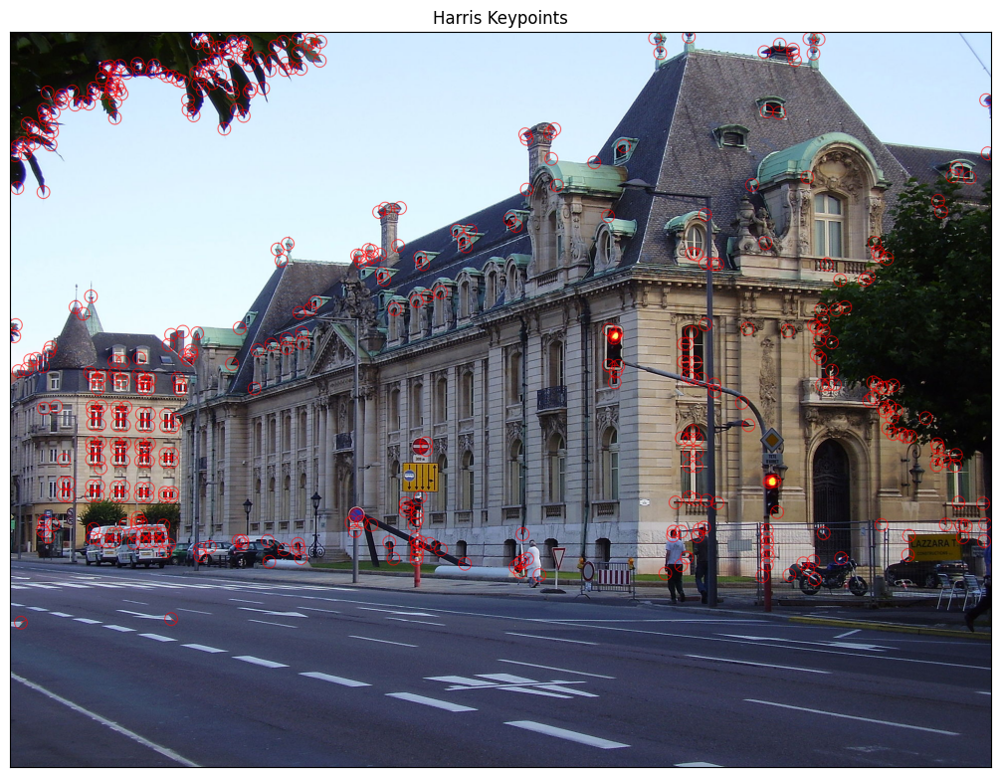

In [ ]:
# A CUBRIR POR EL ALUMNADO
print('Number of detected keypoints: ', len(keypoints))
img = cv2.drawKeypoints(im_gris, keypoints, outImage=im,
      color=(255,0,0),
      flags=cv2.DRAW_MATCHES_FLAGS_DRAW_OVER_OUTIMG
          +cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS)
displayIm(img,'Harris Keypoints',2)

Como se puede comprobar, hemos conseguido una imagen con 490 keypoints. Si comparamos con la imagen original de la plantilla, vemos que el resultado es bastante parecido. Por último, se va a mostrar tanto el mapa de Harris sin umbralizar **Hmap** y el mapa de Harris tras aplicar NMS. Para esto construímos una matriz de 0 de mismas dimensiones que **Hmap** y dejamos a 0 toda posición que no esté en **coord**. Para las posiciones en **coord** se asignará su respectivo valor en **values**.

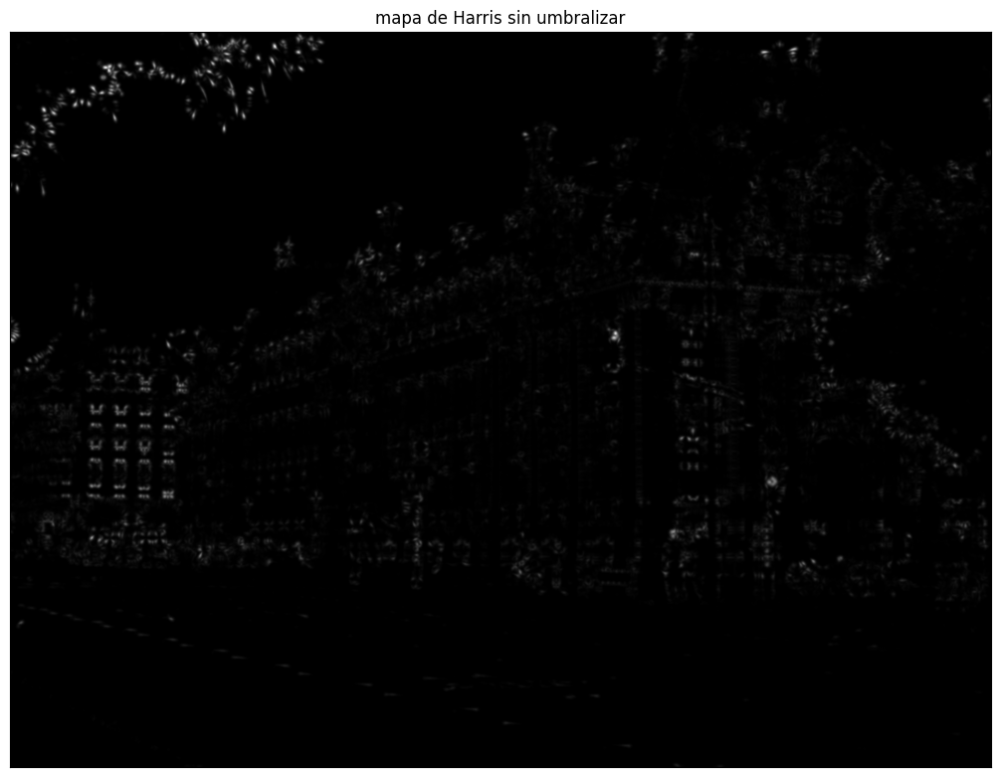

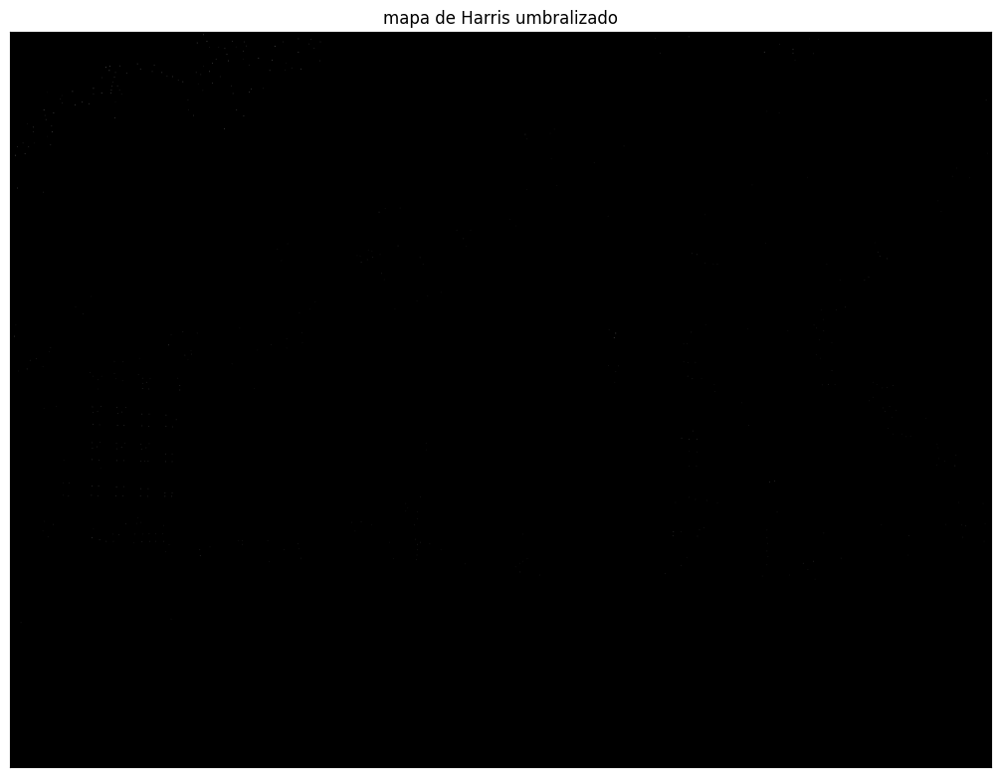

In [ ]:
displayIm(Hmap, 'mapa de Harris sin umbralizar', 2)

# Construimos el mapa umbralizado
Hmap_umb = np.zeros_like(Hmap)
for (row, col), val in zip(coord, values):
    Hmap_umb[row, col] = val
displayIm(Hmap_umb, 'mapa de Harris umbralizado', 2)

Como podemos observar, visualizando Hmap podemos ver puntos blancos que parecen ser los keypoints. Si nos fijamos por ejemplo en las ventanas de la parte izquierda, las hojas de la parte superior izquierda o el árbol de la parte derecha, vemos muchas zonas blancas, lo que coincide con lo visto en la imagen con los keypoints dibujados donde estas zonas son las de mayor densidad de keypoints.

Para la imagen umbralizada, vemos una imagen aparentemente negra entera. Vamos a ver brevemente si la imagen es negra entera.

In [ ]:
print(np.min(Hmap_umb))
print(np.max(Hmap_umb))
mask = Hmap_umb > 0.0
print(np.sum(mask))
print(im.shape, im.shape[0]*im.shape[1])

0.0
0.5969750962750832
490
(1440, 1920, 3) 2764800


Como podemos comprobar, la imagen no es negra entera y tenemos los 490 keypoints tras umbralizar ¿ Por qué se visualiza negra entera entonces ? Al hacer umbralización, tenemos **490 keypoints, es decir, píxeles marcados como mayores que 0.0.** En cambio, nuestra imagen tiene **2,764,800** píxeles que tras umbralización se han dejado a 0 por lo que es razonable que estos píxeles queden escondidos en la visualización y que los píxeles que se vean sean los más de 2,7 millones de píxeles negros.

# <font color='blue'>**Ejercicio 2:** Emparejamiento de _keypoints_ entre imágenes usando descriptores SIFT, Haralick y _Deep Features_ (4 puntos)

<font color='blue'>En este apartado, partiendo de un detector de características (SIFT) y tres descriptores de características (SIFT, _Deep Features_ y Haralick), vamos a calcular el emparejamiento entre _keypoints_ de dos imágenes. Las imágenes con las que se trabajará en este ejercicio serán `IMG_20220312_102942_S.jpg` y `IMG_20220312_102946_S.jpg`. Estas imágenes son de $1200\times1600$ pero, tras leerlas, se debe reducir su tamaño a la mitad ($600\times800$). Es en esta última dimensionalidad en la que realizaremos todo el ejercicio y visualizaremos las imágenes. Y, a continuación, debemos pasarlas a escala de grises. Nota importante: del mismo modo que se calculan _keypoints_ y descriptores en escala de grises, luego los matches/emparejamientos sí se visualizan sobre las imágenes originales en color.

## <font color='blue'>SIFT (Scale-invariant feature transform)

<font color='blue'>En un primer momento, el alumnado debe aplicar el algoritmo SIFT a ambas imágenes para extraer los puntos de interés (_keypoints_) y los descriptores (https://docs.opencv.org/3.4/dc/dc3/tutorial_py_matcher.html). Luego, vamos a emplear tres criterios de emparejamiento: _brute force_ (`cv2.BFMatcher`), _brute force with cross-check_ (`cv2.BFMatcher` con `crossCheck=True`) y el _Lowe's ratio test_ (`knnMatch`) para calcular los emparejamientos y mostrar los $150$ mejores matches utilizando la función `cv2.drawMatches`.

<font color='blue'>En los siguientes apartados, emplearemos exactamente los mismos _keypoints_ detectados por SIFT para calcular otros descriptores en dichas localizaciones y comparar los resultados obtenidos. En los próximos apartados también se utilizarán y compararán los mismos tres criterios de emparejamiento indicados (_BF_, _BF+CC_ y _Lowe's ratio test_).

Vamos a definir la función para calcular los keypoints y descriptores usando **SIFT**.

In [ ]:
# Esta función detecta keypoints y calcula sus descriptores empleando SIFT
def siftPoints(im,nfeatures=5000):
  # A CUBRIR POR EL ALUMNADO
  # Creamos el detector SIFT
  sift = cv2.SIFT_create(nfeatures)
  # Calculamos los keypoints y descriptores
  kp,ds = sift.detectAndCompute(im,None)
  return kp,ds

Una vez tenemos calculados los keypoints y descriptores con SIFT, definimos las operaciones para emparejar keypoints y mostrar tanto keypoints como emparejamientos.

*   La función **showKP** recibe la imagen, los keypoints y un título y muestra la imagen original con los keypoints. Se crea una copia de la imagen sobre la que se dibujarán los keypoints, para no afectar a la imagen original y poder trabajar con ella en los siguientes apartados.
*   La función **showmatches** recibe las dos imágenes con sus keypoints, el vector de matches, el número de los mejores matches a mostrar y un título y muestra las dos imágenes consecutivas con los matches emparejados.
*   La función **matching** construye el vector de matches dados los descriptores de ambas imágenes y el modo, que puede ser **Brute Force, KNN o Brute Force con cross_check**. En el caso de **KNN** se aplica el llamado Lowe's ratio test. Tomamos los 2 mejores matches para cada keypoint y lo consideramos buen match si **mejor.distancia < 0.75 * segundo_mejor.distancia**.


In [ ]:
# Esta función sirve para mostrar los keypoints en la imagen
def showKP(im,kp,title):
  # Dibujamos en la imagen los keypoints con drawKeypoints de openCV
  # Para ello usamos los keypoints de color rojo, las mismas flags que
  # en el ejercicio anterior y la imagen y kp parametros.
  # Creamos la copia de la imagen para no afectar a la original.
  im_copy = im.copy()
  img=cv2.drawKeypoints(im_copy, kp, im_copy,
      color=(255,0,0),
      flags=cv2.DRAW_MATCHES_FLAGS_DRAW_OVER_OUTIMG
          +cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS)

  # Se muestra la imagen con los keypoints
  displayIm(im_copy,title,1)

# Esta función muestra los emparejamientos (matches) entre dos imágenes
def showMatches(im1,kp1,im2,kp2,matches, N, title='Matches'):

  # Usamos la funcion drawmatches que genera una imagen compuesta por las
  # dos imagenes anteriores de forma consecutiva con los keypoints que hacen
  # match. Para ello se le pasa a la funcion ambas imagenes, ambos keypoints,
  # el vector de matches a mostrar y la flag
  # DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS para dibujar solo los puntos que
  # hacen match.
  imBF=cv2.drawMatches(img1,kp1,img2,kp2,matches[:N],
                       None
        ,flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS)

  # Se muestra la imagen con los matches
  displayIm(imBF,title,2)

# Esta función calcula los emparejamientos (matches) entre los descriptores de dos imágenes
def matching(ds1,ds2,FlagMode='BF+CC'):
  if FlagMode=='BF':
    # A CUBRIR POR EL ALUMNADO
    # Se crea el objeto BFMatcher
    bf = cv2.BFMatcher()

    # Se calculan los matches con los descriptores
    matches = bf.match(ds1,ds2)

    # Se ordenan en función de la distancia para obtener los mejores
    # emparejamientos. Se obtiene del ejemplo de la documentacion de openCV
    matches = sorted(matches, key = lambda x:x.distance)

    return matches
  elif FlagMode=='BF+CC':
    # A CUBRIR POR EL ALUMNADO
    # Se crea el objeto BFMatcher pero esta vez con crosscheck
    bf = cv2.BFMatcher(crossCheck=True)

    # Se calculan los matches con los descriptores
    matches = bf.match(ds1,ds2)

    # Se ordenan en función de la distancia para obtener los mejores
    # emparejamientos. Se obtiene del ejemplo de la documentacion de openCV
    matches = sorted(matches, key = lambda x:x.distance)

    return matches
  elif FlagMode=='KNN':
    # A CUBRIR POR EL ALUMNADO
    # Se crea el objeto BFMatcher
    bf = cv2.BFMatcher()

    # Se empareja usando knnMatch con el parametro k=2. Se usa este parametro
    # para obtener los 2 mejores vecinos y aplicar el test de Lowe
    matches = bf.knnMatch(ds1,ds2, k=2)

    # Aplicamos el test de Lowe. Para ello tomamos los dos mejores matches
    # y comprobamos si la distancia del mejor match sigue siendo menor que
    # 0.75 por la distancia al segundo mejor match para asegurarnos de que
    # es un match fuerte
    good = []
    for m,n in matches:
      if m.distance < 0.75*n.distance:
          good.append(m)

    matches = good
    matches = sorted(matches, key = lambda x:x.distance)
    return matches
  else:
    return print('Error in Matching mode')


A continuación leemos las imagenes a la mitad de tamaño original y también tomamos sus versiones en escala de grises.

In [ ]:
img1=cv2.resize(readIm(get_image('IMG_20220312_102942_S.jpg'),1), (0,0), fx=0.5, fy=0.5) #
im1=cv2.cvtColor(img1,cv2.COLOR_RGB2GRAY)
img2=cv2.resize(readIm(get_image('IMG_20220312_102946_S.jpg'),1), (0,0), fx=0.5, fy=0.5) #
im2=cv2.cvtColor(img2,cv2.COLOR_RGB2GRAY)

Vamos a calcular los keypoints para visualizarlos.

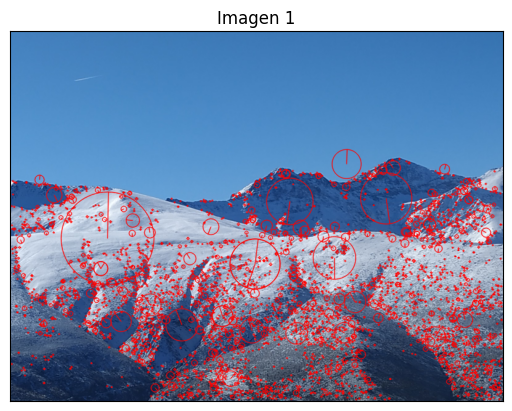

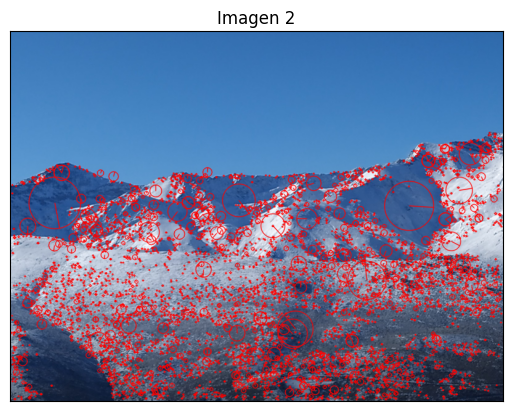

In [ ]:
# Calculamos los kp y descriptores
kp1, ds1 = siftPoints(im1)
kp2, ds2 = siftPoints(im2)
showKP(img1,kp1,'Imagen 1')
showKP(img2,kp2,'Imagen 2')

Como se puede comprobar, tenemos muchos keypoints. Entre los cuáles destacan algunos como el keypoint de circunferencia muy amplia a la izquierda de la segunda imagen que es común a ambas imágenes.
Vamos ahora a hacer el matching, Para ello:
1.  Calculamos los keypoints y descriptores de ambas imágenes en gris.
2.  Calculamos los matches con la función anterior de las tres maneras diferentes.
3.  Mostramos los matches entre las imágenes a color.

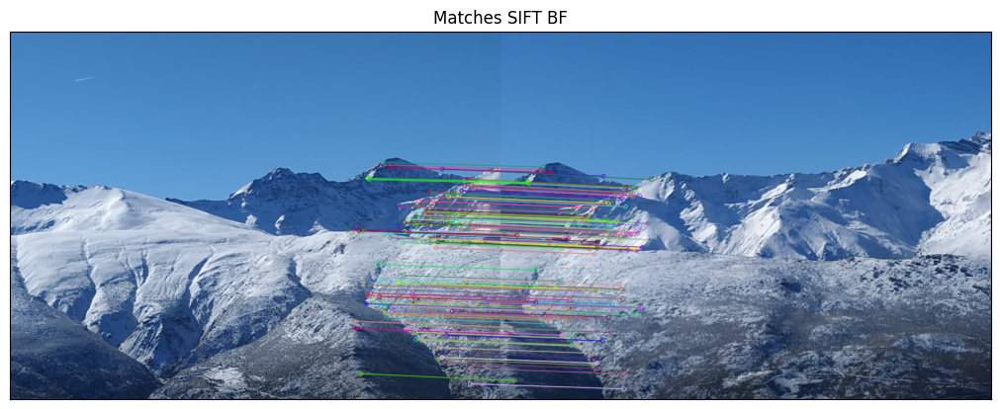

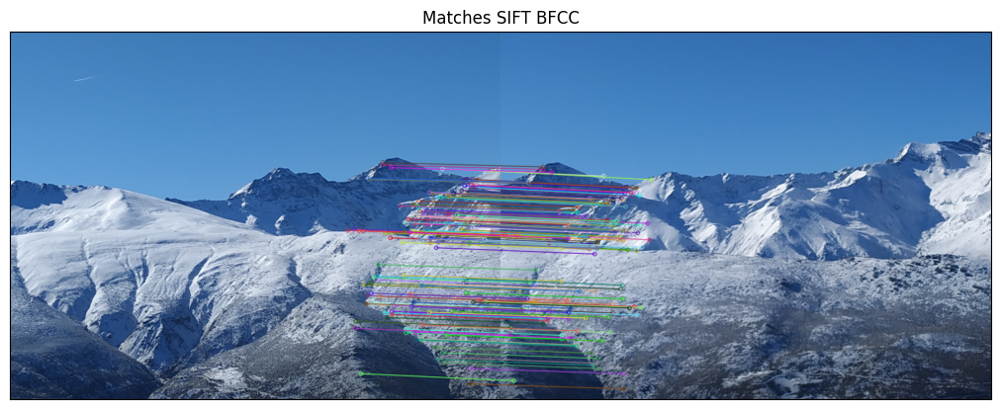

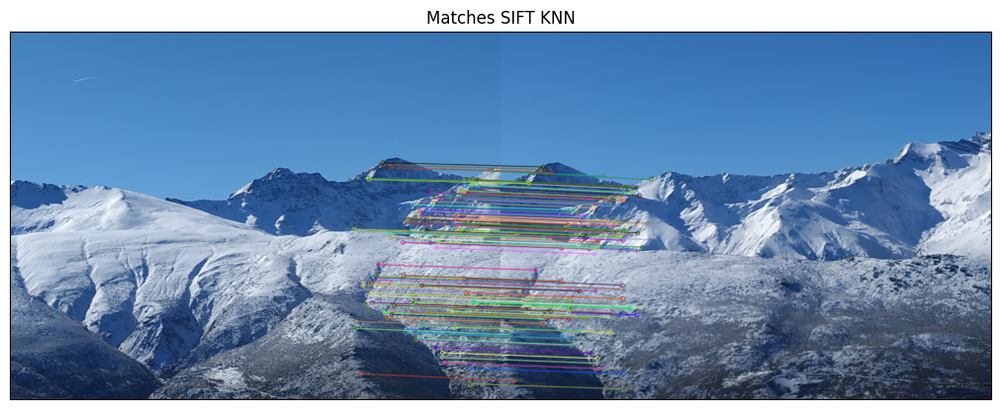

In [ ]:
# A CUBRIR POR EL ALUMNADO
# Calculamos los kp y descriptores
kp1, ds1 = siftPoints(im1)
kp2, ds2 = siftPoints(im2)

# Calculamos los matches con BF, BF+CC y KNN
matches_BF = matching(ds1,ds2,'BF')
matches_BF_CC = matching(ds1,ds2,'BF+CC')
matches_KNN = matching(ds1,ds2,'KNN')

# Mostramos los matches
showMatches(img1,kp1,img2,kp2,matches_BF, 150, 'Matches SIFT BF')
showMatches(img1,kp1,img2,kp2,matches_BF_CC, 150, 'Matches SIFT BFCC')
showMatches(img1,kp1,img2,kp2,matches_KNN, 150, 'Matches SIFT KNN')




Observaciones:
*   Tanto **BF** como **BF cross-check** como **KNN** muestran resultados muy parecidos, donde podemos ver que la imagen de la derecha contiene una pequeña parte de la imagen de la izquierda y su continuación, por lo que detecta muy bien esos matches de los elementos comunes.

*   Este resultado es coherente porque como vimos en teoría, los descriptores SIFT son invariantes a traslaciones rotaciones y cambios de escala, por lo que aun siendo  imágenes diferentes, al contener elementos comunes en posiciones diferentes ( traslación y quizá algo de rotación ) y al haber tomado las imégenes presumiblemente a una distancia diferente ( cambios de escala ) el emparejamiento de descriptores es muy bueno.


## <font color='blue'>Haralick Texture Features

<font color='blue'>Ahora, vamos a hacer lo mismo de antes, pero empleando las características de Haralick (del paquete `mahotas`: `mahotas.features.haralick`). Para ello debemos crear una pequeña ventana ($7\times7$ pixels) centrada en torno a los SIFT keypoints detectados, y calcular el vector de características correspondiente.



In [ ]:
!pip install mahotas

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.8/5.8 MB 51.9 MB/s eta 0:00:00


Ahora vamos a obtener los descriptores utilizando **Haralick texture features**. Esta funcionalidad permite calcular un vector de features de 13 componentes. Realiza el cálculo en base a la matriz de adyacencia donde en la posición **(i,j)** se guarda las veces que un píxel con valor i está al lado de un píxel de valor j. Se devuelve realmente una matriz con valores de features en 4 direcciones y la práctica habitual es calcular la media en cada columna, es decir, cada feature.

Para utilizar haralick, tenemos que definir una ventana de 7x7 centrada en cada keypoint ( usaremos los proporcionados por SIFT ). A esta ventana se le aplicará haralick para obtener los descriptores. Cabe resaltar que solo se van a tener en cuenta los keypoints que tengan una ventana que no se salga del rango de la imagen.

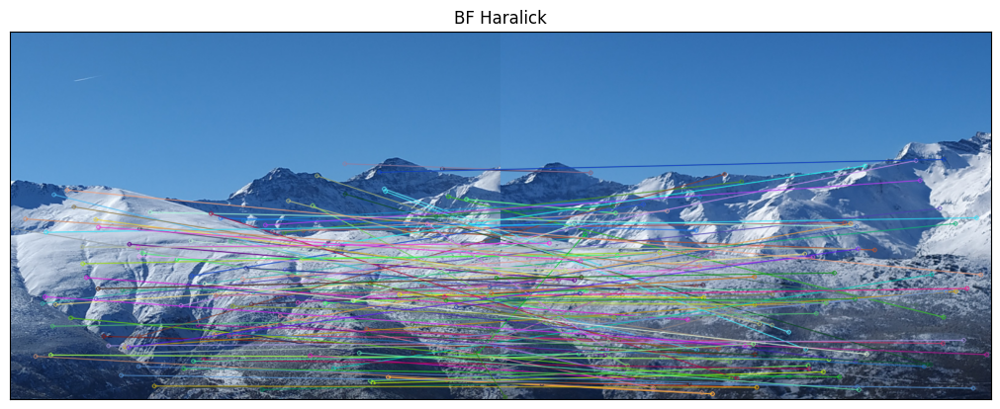

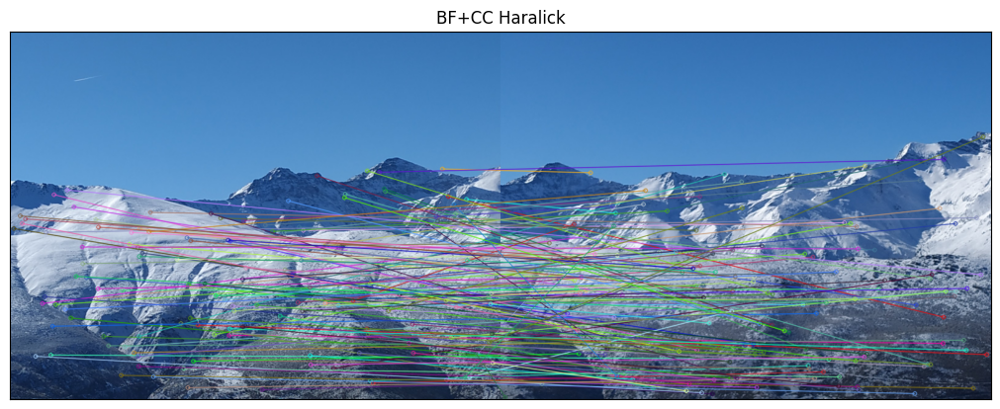

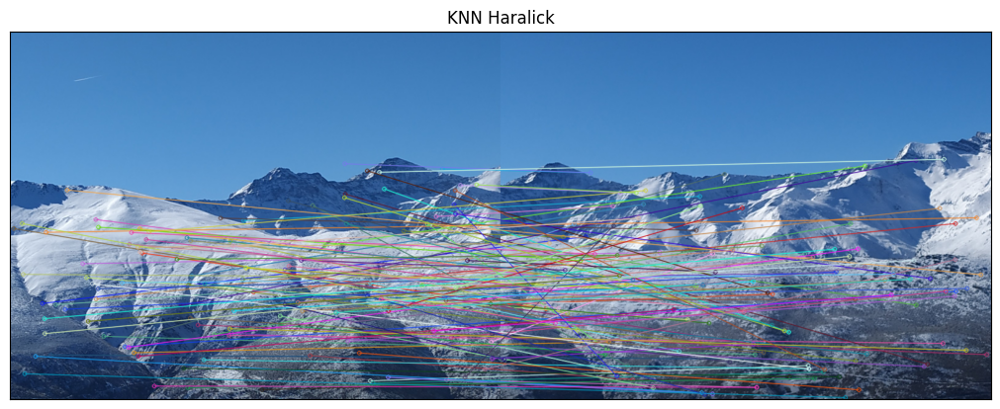

In [ ]:
# A CUBRIR POR EL ALUMNADO

from mahotas.features import haralick
# Definimos la lista de keypoints y descriptores de haralick
kp1_window = []
haralick_kp1 = []

for kp in kp1:

  # Tomamos las coordenadas de los keypoints
  x,y = int(kp.pt[0]),int(kp.pt[1])

  # Comprobamos si podemos calcular la ventana 7x7 centrada
  # en el keypoint
  if( (x - 3) >= 0 and (x + 3) < im1.shape[1]
     and (y - 3) >= 0 and (y + 3) < im1.shape[0] ):
    ventana = im1[y-3:y+4, x-3:x+4]

    # Calculamos el descriptor
    hl1 = haralick(ventana).mean(axis=0)

    kp1_window.append(kp)
    haralick_kp1.append(hl1)

# Definimos la lista de keypoints y descriptores de haralick
kp2_window = []
haralick_kp2 = []

for kp in kp2:

  # Tomamos las coordenadas de los keypoints
  x,y = int(kp.pt[0]),int(kp.pt[1])


  # Comprobamos si podemos calcular la ventana 7x7 centrada
  # en el keypoint
  if( (x - 3) >= 0 and (x + 3) < im2.shape[1]
     and (y - 3) >= 0 and (y + 3) < im2.shape[0] ):

    ventana = im2[y-3:y+4, x-3:x+4]

    # Calculamos el descriptor
    hl2 = haralick(ventana).mean(axis=0)
    kp2_window.append(kp)
    haralick_kp2.append(hl2)

# Convertimos los descriptores a float que es lo que acepta BFmatcher
haralick_kp1 = np.array(haralick_kp1, dtype=np.float32)
haralick_kp2 = np.array(haralick_kp2, dtype=np.float32)

# Calculamos los matches con los nuevos kp y desc
matches_BF = matching(haralick_kp1,haralick_kp2,'BF')
matches_BF_CC = matching(haralick_kp1,haralick_kp2,'BF+CC')
matches_KNN = matching(haralick_kp1,haralick_kp2,'KNN')

# Mostramos los matches
showMatches(img1,kp1_window,img2,kp2_window,matches_BF, 150,'BF Haralick')
showMatches(img1,kp1_window,img2,kp2_window,matches_BF_CC, 150,'BF+CC Haralick')
showMatches(img1,kp1_window,img2,kp2_window,matches_KNN, 150,'KNN Haralick')


Como se puede comprobar, el matching a nivel visual es incorrecto. Sabemos que la imagen derecha contiene parte de la imagen de la izquierda y su continuación. Vemos como se producen matches entre puntos de la izquierda de la imagen izquierda y la derecha de la imagen derecha lo cuál no tiene sentido pues los elementos relacionados no aparecen en la imagen del otro punto de match. Vamos a visualizar menos matches para intentar sacar alguna conclusión.

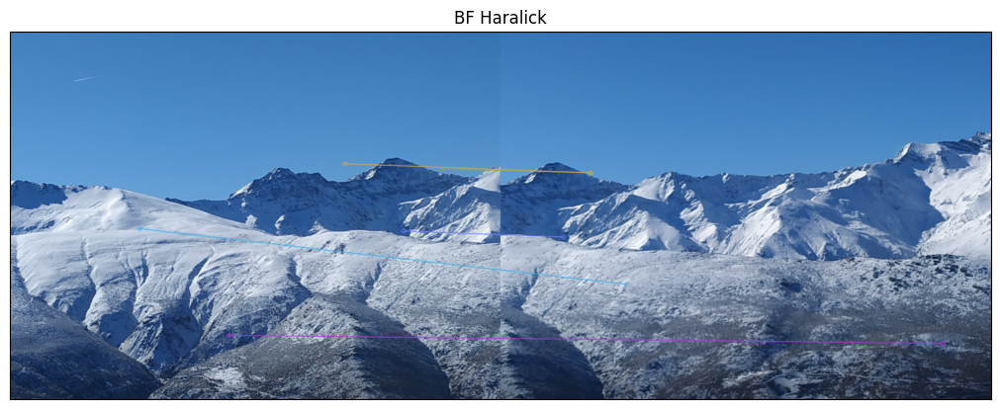

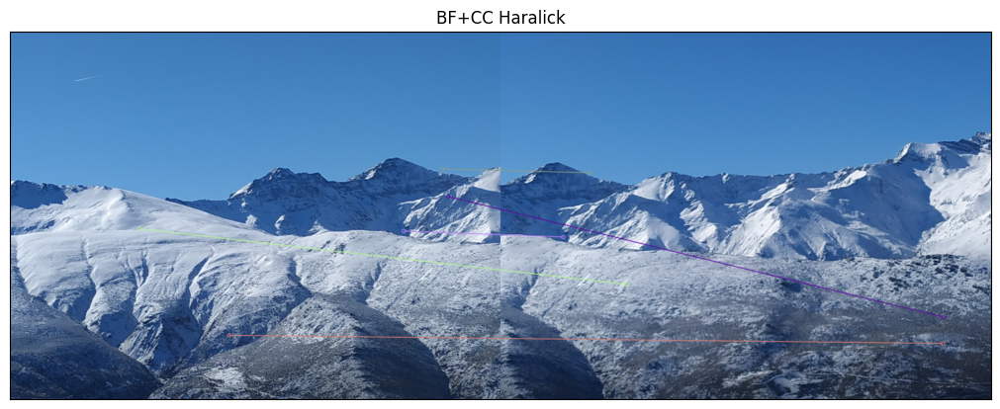

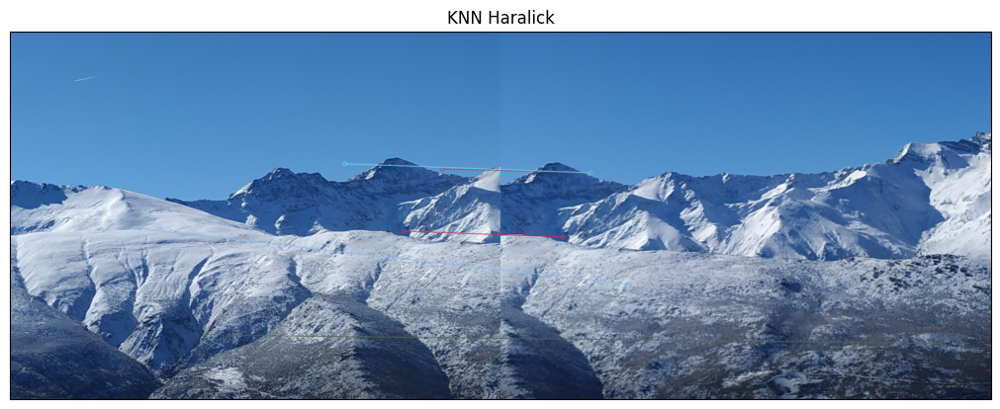

In [ ]:
# Mostramos 5 matches
showMatches(img1,kp1_window,img2,kp2_window,matches_BF, 5,'BF Haralick')
showMatches(img1,kp1_window,img2,kp2_window,matches_BF_CC, 5,'BF+CC Haralick')
showMatches(img1,kp1_window,img2,kp2_window,matches_KNN, 5,'KNN Haralick')

Como podemos comprobar, realmente solo tenemos un match correcto que es el representado por la línea más corta localizada aproximadamente en la mitad de altura de la imagen. Aun así como podemos ver en la línea de mayor altura y en otras, realmente lo que estamos viendo es un match de texturas. Esto se debe a que Haralick está diseñado para la detección de texturas y no entiende de localización, por lo que no es un método correcto para hacer matching espacial de keypoints.

## <font color='blue'>_Deep Features_

<font color='blue'>Ahora hacemos lo mismo, pero con _deep features_, es decir, características extraídas por medio de una red profunda. En concreto, el alumnado debe emplear ResNet50 preentrenada y, a la hora de aplicarla en inferencia sobre un _image patch_ (de tamaño $1.5$ veces el `kp.size` detectado por SIFT), quedarse con un vector de dimensionalidad $2048$ (dimensionalidad de salida tras el _global average pooling_ previo a la _fully connected layer_ con $1000$ unidades, debido a las $1000$ clases de ImageNet). El alumnado debe acordarse de ejecutar la GPU en este apartado. De lo contrario, la ejecución puede ser excesivamente lenta.

Para este apartado necesitamos los siguientes pasos:
*   Definir el modelo **resnet50 preentrenado.**
*   Quitar la última capa FC para tener el vector de dimensión 2048 que proporciona la capa anterior. Para ello usamos la función **children** de pytorch que devuelve un iterador sobre las capas del modelo y hacemos una lista quedándonos con todas menos la última. Por último se crea el modelo utilizando secuencialmente estas capas. La implementación de este bloque ha sido ayudada por ChatGPT que me ha indicado como convertir todas estas capas children a una lista. En fastai se hace diferente pero como en fastai necesitamos para construir un learner un dataloaders, se ha optado por usar pytorch.
*   Crear un transformer de pytorch para aplicar a nuestro patch. Necesitamos redimensionar a 224x224 que es el tamaño que usa resnet50, convertirlo a tensor y además normalizaremos la entrada. Esto lo hacemos con Compose de pytorch que crea un pipeline de transformaciones a aplicar.
*   Para cada keypoint, generamos el patch centrado en el keypoint de tamaño **1.5 * kp.size** ( si se puede, si se sale del rango de la imagen se descarta).
*   Este patch se pasa un tipo de dato **PILImage** que según la documentación https://docs.pytorch.org/vision/stable/transforms.html, es común pasar a este tipo de datos para aplicar transformers.
*   Se aplica el transformer al patch.
*   Se pasa el patch al modelo para calcular el descriptor. Se pasa en modo torch.no_grad() pues solo necesitamos obtener la salida y no nos aporta nada el cálculo de gradientes pues no estamos entrenando el modelo.

/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=ResNet50_Weights.IMAGENET1K_V1`. You can also use `weights=ResNet50_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


Downloading: "https://download.pytorch.org/models/resnet50-0676ba61.pth" to /root/.cache/torch/hub/checkpoints/resnet50-0676ba61.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 236MB/s]


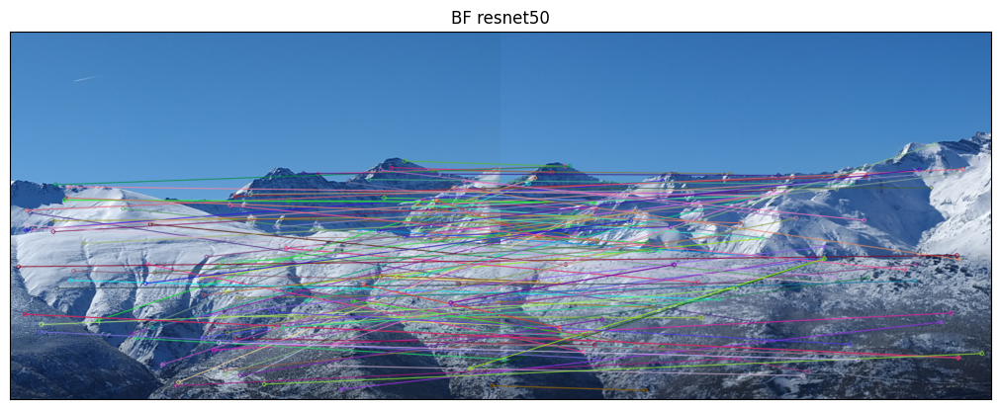

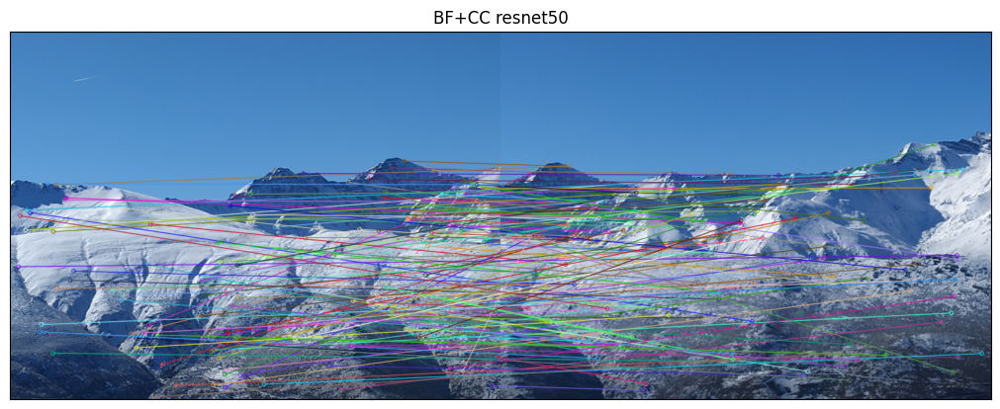

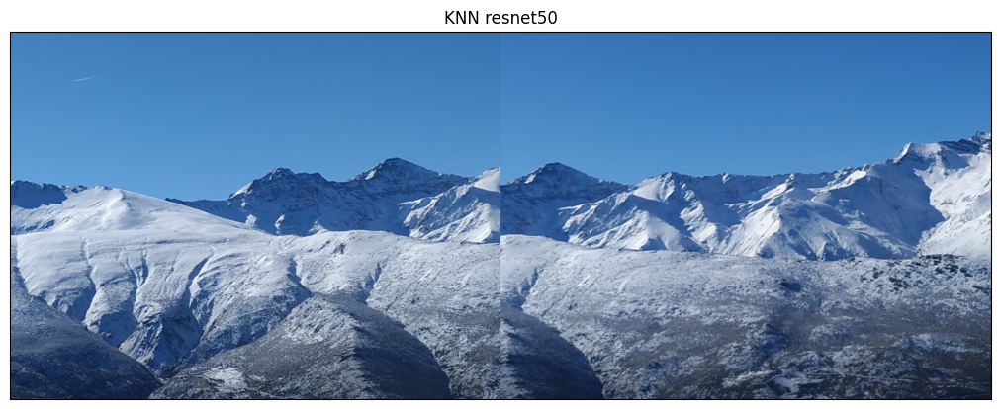

In [ ]:
# A CUBRIR POR EL ALUMNADO
from fastai.vision.all import *
from torch import nn

# Construimos el modelo resnet50 sin la ultima capa FC
modelo  = resnet50(pretrained= True)
modelo_sin_FC = nn.Sequential(*list(modelo.children())[:-1])

# Necesitaremos aplicar una serie de transformaciones  al patch. Para
# ello definimos un transformer utilizando Compose de pytorch que hace
# las siguientes cosas:
# - Amplia la imagen a tamaño 224x224 que es el tamaño de resnet.
# - Convierte el patch a tensor.
# - Normaliza el tensor con datos de imagenet.

import torchvision.transforms as T

tfm = T.Compose([
    T.Resize((224,224)),
    T.ToTensor(),
    T.Normalize(*imagenet_stats)
])
# Definimos la lista de keypoints y descriptores de resnet
kp1_window = []
resnet_kp1 = []


for kp in kp1:
  # Tomamos las coordenadas de los keypoints
  x,y = int(kp.pt[0]),int(kp.pt[1])

  # definimos el tamaño del patch
  tam_patch = 1.5 * kp.size
  dist_centro = int(tam_patch // 2)

  # Comprobamos si podemos calcular la ventana de tamaño 1.5 x kp.size
  if( (x - dist_centro) >= 0 and (x + dist_centro) < im1.shape[1]
     and (y - dist_centro) >= 0 and (y + dist_centro) < im1.shape[0] ):
    patch = img1[y-dist_centro:y+dist_centro + 1, x-dist_centro:x+ dist_centro + 1]


    # Para aplicar el transformer necesitamos pasar el dato a tipo PILImage
    patch_pil = PILImage.create(patch)

    # Ahora aplicamos las transformaciones al patch para pasarlo por el modelo.
    # El uso de unsqueeze nos lo proporciona ChatGPT porque si dejamos el patch
    # solo aplicando tfm, nos falta la dimensión del batch, que es lo que
    # proporciona unsqueeze(0), agregando una dimension en la posicion 0.
    patch = tfm(patch_pil).unsqueeze(0)

    # Calculamos el descriptor
    with torch.no_grad():
      des = modelo_sin_FC(patch).flatten()

    kp1_window.append(kp)
    resnet_kp1.append(des)

# Definimos la lista de keypoints y descriptores de resnet
kp2_window = []
resnet_kp2 = []
for kp in kp2:

  # Tomamos las coordenadas de los keypoints
  x,y = int(kp.pt[0]),int(kp.pt[1])

  # definimos el tamaño del patch
  tam_patch = 1.5 * kp.size
  dist_centro = int(tam_patch // 2)

  # Comprobamos si podemos calcular la ventana de tamaño 1.5 x kp.size
  if( (x - dist_centro) >= 0 and (x + dist_centro) < im1.shape[1]
     and (y - dist_centro) >= 0 and (y + dist_centro) < im1.shape[0] ):
    patch = img2[y-dist_centro:y+dist_centro + 1, x-dist_centro:x+ dist_centro + 1]


    # Ahora aplicamos las transformaciones al patch para pasarlo por el modelo.
    # El uso de unsqueeze nos lo proporciona ChatGPT porque si dejamos el patch
    # solo aplicando tfm, nos falta la dimensión del batch, que es lo que
    # proporciona unsqueeze(0), agregando una dimension en la posicion 0.
    patch_pil = PILImage.create(patch)
    patch = tfm(patch_pil).unsqueeze(0)

    # Calculamos el descriptor
    with torch.no_grad():
      des = modelo_sin_FC(patch).flatten()

    kp2_window.append(kp)
    resnet_kp2.append(des)


# Convertimos los descriptores a float que es lo que acepta BFmatcher
resnet_kp1 = np.array(resnet_kp1, dtype=np.float32)
resnet_kp2 = np.array(resnet_kp2, dtype=np.float32)

# Calculamos los matches con los nuevos kp y desc
matches_BF = matching(resnet_kp1,resnet_kp2,'BF')
matches_BF_CC = matching(resnet_kp1,resnet_kp2,'BF+CC')
matches_KNN = matching(resnet_kp1,resnet_kp2,'KNN')

# Mostramos los matches
showMatches(img1,kp1_window,img2,kp2_window,matches_BF, 150,'BF resnet50')
showMatches(img1,kp1_window,img2,kp2_window,matches_BF_CC, 150,'BF+CC resnet50')
showMatches(img1,kp1_window,img2,kp2_window,matches_KNN, 150,'KNN resnet50')


En este caso, por alguna razón vemos que no existen matches usando KNN. Vamos a ver si hay algún match o si realmente ninguno pasa el test de lowe.

In [ ]:
print(len(matches_BF))
print(len(matches_BF_CC))
print(len(matches_KNN))

3636
594
0


En efecto, parece ser que el test de Lowe es el que está haciendo que se descarten todos los keypoints. Esto nos dice que el mejor match detectado por knnMatch usando descriptores de resnet50, no es suficientemente mejor que el segundo y por tanto no se acepta. Además, si nos fijamos en los keypoints y sus matches en BF y BF+CC, tenemos una problemática similar cuando usamos haralick, donde vemos matches entre elementos que no son comunes a las dos imágenes. Al igual que con haralick, vamos a mostrar los 5 mejores matches para intentar sacar alguna conclusión.

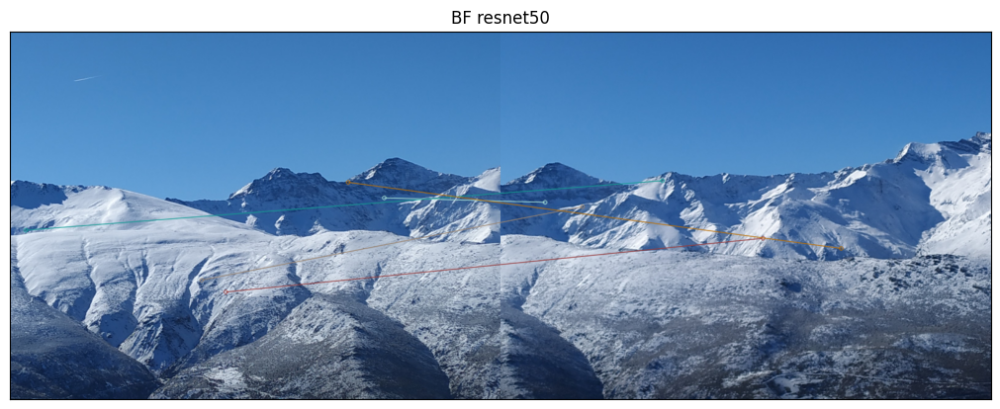

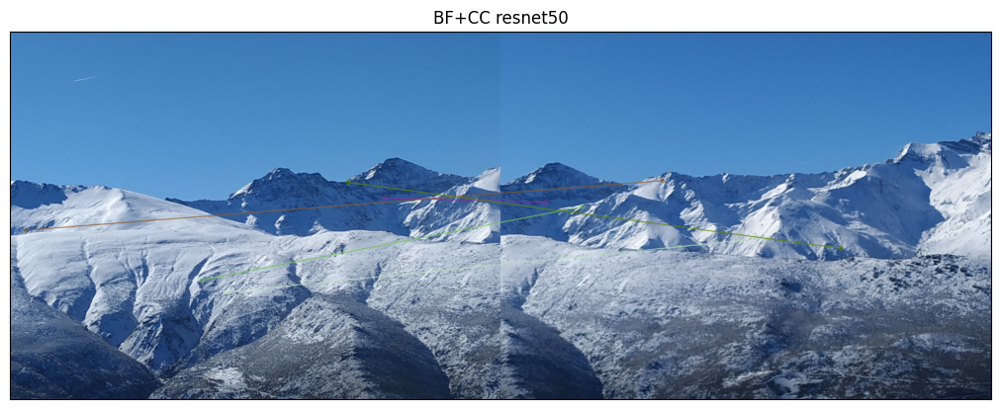

In [ ]:
# Mostramos los matches
showMatches(img1,kp1_window,img2,kp2_window,matches_BF, 5,'BF resnet50')
showMatches(img1,kp1_window,img2,kp2_window,matches_BF_CC, 5,'BF+CC resnet50')

Al igual que con Haralick, podemos ver que se está realizando matches entre puntos donde las características son similares en cuanto a apariencia. Por ejemplo, la línea verde oscura de BF + CC parece relacionar dos puntos afectados por sombra. En cambio, parece que no detecta bien la correspondencia en posición de los keypoints, como vimos que en SIFT si que pasaba. Esto se da porque resnet50 está entrenada para la clasificación de imágenes y por tanto está asociada a detectar el qué, no el dónde.

<font color='blue'> ¿Cuál de los descriptores anteriores parece más adecuado para _keypoint matching_ y por qué?

*   En base a los experimentos realizados, tenemos que claramente destaca **SIFT por encima de los demás**. Vemos una clara correspondencia entre los puntos más a la derecha de la primera imagen con los primeros de la segunda imagen, lo cuál es lógico pues la segunda es continuación de la primera. Este resultado es coherente porque como vimos en teoría, los descriptores SIFT son invariantes a traslaciones rotaciones y cambios de escala, por lo que aun siendo  imágenes diferentes, al contener elementos comunes en posiciones diferentes ( traslación y quizá algo de rotación ) y al haber tomado las imégenes presumiblemente a una distancia diferente ( cambios de escala ) el emparejamiento de descriptores es muy bueno.
*   En cuanto a por qué **Haralick** es claramente peor, hemos visto que parece relacionar elementos de texturas similares. Esto es totalmente lógico pues Haralick está diseñado para obtener texturas.
*   Para **resnet50**, al igual que con Haralick, vemos unos resultados mucho peores que SIFT. Como hemos comentado, resnet50 está pensada para la clasificación de imágenes, por lo que detecta características en lugar de correspondencia espacial entre imágenes.

# <font color='blue'>**Ejercicio 3:** Creación de panoramas/mosaicos (_Image Stitching_) empleando homografías (4 puntos)

<font color='blue'>Ahora vamos a calcular homografías entre imágenes y usarlas para construir un mosaico/panorama. Para calcular la homografía entre dos imágenes, hay que llamar a la función `cv2.findHomography()`, que toma como entrada las listas de _keypoints_ y los matches/emparejamientos encontrados. Se debe usar RANSAC para realizar una estimación robusta.

Vamos a definir la función para calcular la homografía entre dos imágenes. Nuestra función recibe los keypoints de cada imagen, el vector de matches,
el error de RANSAC y la cantidad mínima de matches aceptada y calcula la homografía de la siguiente forma:
1.  Comprueba si la cantidad de matches es mayor que el mínimo aceptado, es decir **MIN_MATCH_COUNT**.
2.  En ese caso calcula los puntos de la primera imagen **src** y los de la segunda imagen **dst**. Para calcular estos puntos, accedemos a cada match y cada objeto match contiene el índice del keypoint en el vector de descriptores de la primera imagen ( **queryIdx**) y el índice del keypoint emparejado de la segunda imagen ( **trainIdx** ). Construímos la lista de estos puntos en formato **np.float32** que es uno de los formatos aceptados por **findHomography(...)**.
3.  Calculamos la homografía con **findHomography(...)**, con los puntos de la primera imagen **src** y la segunda imagen **dst**, utilizando el método **RANSAC** y usando el **Ransac_error** que se pasa como parámetro. El método RANSAC se basa principalmente en encontrar cuáles son los inliers ( correspondencias verdaderas ) y outliers ( falsas correspondencias ) y estimar el modelo ( en nuestro caso el cálculo de homografías ) en base a los inliers.

In [ ]:
# Esta función calcula la homografía entre dos imágenes.
def homography(kp1,kp2,matches, Ransac_Error,MIN_MATCH_COUNT):

  # 1. Se comprueba si el numero de matches supera el minimo
  if len(matches)>MIN_MATCH_COUNT:
    # A CUBRIR POR EL ALUMNADO

    # 2. Se calcula los puntos de cada match.
    #    primera imagen -> kp1[match.queryIdx]
    #    segunda imagen -> kp2[match.trainIdx]
    src = np.float32([ kp1[m.queryIdx].pt for m in matches ])
    dst = np.float32([ kp2[m.trainIdx].pt for m in matches ])

    # Se calcula la homografía usando los puntos src y dst,
    # con metodo Ransac y Ransac_error
    H, mask = cv2.findHomography(srcPoints = src,
                                 dstPoints = dst,
                                 method = cv2.RANSAC,
                                 ransacReprojThreshold = Ransac_Error)

  else:
     print('Error - very few matches')
  return H

<font color='blue'>Para componer el mosaico necesitamos realizar los siguientes pasos:

> <font color='blue'>a) Escoger un tamaño máximo para el lienzo/canvas/fondo sobre el que vamos a pegar y "encajar" todas las imágenes (tamaño que depende del número de imágenes a unir/componer y sus dimensiones).

> <font color='blue'>b) Escoger la imagen central que dará los ejes al mosaico (que debemos escoger con criterio, de cara a mejorar la calidad final del mosaico).

> <font color='blue'>c) Establecer el orden de cada imagen respecto a la central (es decir, podemos asumir que, a priori, conocemos la posición de cada imagen en la serie de imágenes tomadas y, como consecuencia, conocemos qué imágenes están a la derecha y/o a la izquierda de otras; en otras palabras, conocemos el orden en que fueron tomadas las fotografías en el movimiento de izquierda a derecha sacando la panorámica).

> <font color='blue'>d) Calculamos la homografía para copiar la imagen central en el lienzo (que es solamente una traslación).

> <font color='blue'>e) A continuación, debemos ir leyendo las imágenes de izquierda a derecha (recordemos que asumimos que conocemos el orden de adquisición de las imágenes), y debemos calcular la homografía entre cada par de imágenes consecutivas.

> <font color='blue'>f) Con la información anterior, debemos componer la homografía entre cada imagen y el lienzo/canvas. Es decir, la matriz que lleva cada imagen/foto a su posición correcta en el lienzo.

> <font color='blue'>g) Ahora, debemos utilizar las homografías calculadas para transportar las imágenes al lienzo (por medio de la función `cv2.warpPerspective()`). Es importante ir de fuera hacia dentro, es decir, desde los extremos hasta el centro, pegando en último término la imagen central, que es la que presentará un menor grado de deformación (porque la única transformación que se le aplicará será una pura traslación).

> <font color='blue'>i) Finalmente, debemos eliminar las regiones negras de los bordes del canvas para mejorar la calidad final del mosaico.

<font color='blue'>Se deben componer dos mosaicos:

- <font color='blue'>uno, relativo a fotografías tomadas desde la ETSIIT (imágenes `mosaico002.jpg`,`mosaico003.jpg`,`mosaico004.jpg`,`mosaico005.jpg`,`mosaico006.jpg`,
           `mosaico007.jpg`,`mosaico008.jpg`,`mosaico009.jpg`,`mosaico010.jpg`,`mosaico011.jpg`).

- <font color='blue'>otro, empleando las fotografías del Hall (imágenes `Picture1.jpg`,`Picture2.jpg`,`Picture3.jpg`,`Picture4.jpg`,`Picture5.jpg`,`Picture6.jpg`,`Picture7.jpg`,`Picture8.jpg`).

<font color='blue'>Se debe mostrar la composición, paso a paso, del canvas, es decir, el canvas a medida que se le van incorporando cada una de las imágenes, así como la composición final del mosaico (incluyendo una explicación relativa a si alguno de los dos mosaicos es más difícil de componer que el otro y por qué). Finalmente, se debe comparar el resultado de nuestra composición manual con el _stitcher_ de OpenCV: `cv2.Stitcher()`.

<font color='blue'>Al igual que en todas las demás entregas y ejercicios, resulta fundamental documentar el trabajo realizado, y explicar pausadamente todas las etapas implementadas (qué se ha hecho, cómo se ha hecho, y por qué se ha hecho así).


Vamos a definir ahora operaciones relativas al cálculo de homografías. Antes de definir estas funciones, vamos a hacer una aclaración sobre las homografías. Consultando el siguiente enlace (https://es.wikipedia.org/wiki/Homograf%C3%ADa_(geometr%C3%ADa)), tenemos en el apartado **propiedades** la siguiente afirmación: Si **$f$** es una homografía, entonces **$f$** es biyectiva y su inversa es la homografía dada por **$f^{-1}$**. Esto significa que si tenemos una imagen **A** y una imagen **B** y **$f(A) = B$** entonces **$f^{-1}(B) = A$**. Por tanto si H12 es la matriz que representa la homografía de la imagen 1 a la imagen 2 entonces $H21$ = $H12^{-1}$. Además, si nos fijamos en la **diapositiva 100** del guión, vemos como se realiza la composición de homografías. Como hemos visto, aplicar la homografía **$f$** al punto **p** es lo mismo que multiplicar la matriz de la homografía por el punto **p** --> **$Hp$**. Entonces las homografías que se aplican primero son las que están a la derecha. Por ejemplo si tenemos 5 imágenes, el orden para llevar de la imagen 1 a la 5 será **$H45 H34 H23 H12$**.
Las funciones son las siguientes:



*  **computeLocalHomographies(images,method='KNN', Ransac_Error=5.0,Min_Match_Count=25)**: Esta función recibe una lista de imágenes, un método de matching, el error de Ransac y el mínimo de matches aceptado y calcula el vector de homografías donde **H[i] = homografía de la imagen i a la imagen i+1**. Para ello calculamos los keypoints y descriptores de cada imagen, los emparejamientos entre ellos y por último la homografía entre las imágenes.

*   **mosaicHomographies(H,idx)**: Esta función calcula las transformaciones que hay que aplicar a cada imagen para llevarla al centro de la imagen. Se nos dice que es para llevarla al canvas pero realmente esto no es así, pues no se especifica como la operación de traslación como parámetro en la definición de la función aportada. Podríamos hacer una llamada dentro de la función para calcular la homografía de traslación al canvas pero entonces el parámetro **H0** de la función **composeMosaic** (que explicaremos más adelante) carecería de sentido. La función devuelve un vector formado por las transformaciones para llevar la imagen de **índice i** al centro. Este vector tiene una componente más que el vector de transformaciones de la función anterior. Esto es porque este vector representa las operaciones que hay que aplicar para llevar a cada imagen ( junto con H0 ) a su posición en el canvas y por tanto necesitamos una operación para cada imagen. En cambio, el vector de homografías era entre pares de imágenes, luego la última imagen no tiene asociada una homografía porque es la última imagen. Para calcular estas operaciones, tenemos en cuenta la propiedad de las inversas que hemos citado previamente. Distinguimos tres casos:
    1.  **Imágenes a la izquierda del centro**. En este caso tenemos que para cada imagen, las operaciones para llevar esa imagen al centro es las operaciones que llevan la siguiente imagen al centro por la homografía que lleva esa imagen en la siguiente , es decir:
    $$
    H_{canvas}[i] = H_{canvas}[i+1] H[i] , \text{  i = {0,1,.., idx - 1 }}
    $$
    Esto lo sabemos por lo que hemos descrito previamente sobre composición de homografías.
    2.  **Imagen central**. Esta imagen ya se encuentra en su sitio, por lo que:
    $$
    H_{canvas}[idx] = I_3
    $$
    3. **Imágenes a la derecha del centro**. Este caso es muy parecido al caso 1 solo que tenemos que tener en cuenta que hemos calculado las **homografías de i en i+1** y aquí necesitamos las **homografías de i en i-1**. Aplicamos el mismo concepto de composición donde las operaciones que se aplican primero están más a la derecha y que $H_{i,i+1}^{-1} = H_{i+1,i}$. En este caso, la operación para una imagen será las operaciones de la imagen anterior por la homografía que lleva la imagen en la anterior. Por tanto:
    $$
    H_{canvas}[i] = H_{canvas}[i-1] H[i-1]^{-1} , \text{  i = {idx + 1,.., n_images }}
    $$


*   **axesHomography(sizeim,sizecanvas)**: Calcula la homografía de traslación de la imagen central al canvas.


In [ ]:
import numpy as np
# Esta función calcula las homografías entre cada par de imágenes consecutivas.
# Internamente llama a homography().
def computeLocalHomographies(images,method='KNN', Ransac_Error=5.0,Min_Match_Count=25):
  H=[]

  for item in range(0,len(images)-1):
    # A CUBRIR POR EL ALUMNADO

    # Calculamos los keypoints y descriptores con SIFT
    kp1, ds1 = siftPoints(images[item])
    kp2, ds2 = siftPoints(images[item+1])

    # Calculamos los matches
    matches = matching(ds1,ds2,method)

    # Calculamos las homografias entre una imagen y la siguiente
    Haux=homography(kp1, kp2, matches, Ransac_Error, Min_Match_Count)
    H.append(Haux)
  return H

# Esta función calcula/compone la homografía para trasladar cada imagen al canvas.
# idx sería el índice de la imagen central
def mosaicHomographies(H,idx):
  # A CUBRIR POR EL ALUMNADO
  # Definimos la lista de operaciones para llevar cada imagen al canvas
  # (salvo traslacion H0). Por tanto necesitamos tantas como imagenes
  H_canvas = [None] * ( len(H) + 1 )

  # La imagen central se encuentra en el centro, luego la operacion es
  # la identidad de orden 3. Caso 2
  H_canvas[idx] = np.eye(3)

  # Caso 1. Imagenes a la izquierda del centro. Teniendo en cuenta como
  # funciona la composicion de homografias y como se aplica una homografia
  # en forma matricial, tenemos que H_canvas H_canvas[i] = H_canvas[i+1] @ H[i]
  # Por ejemplo si tenemos 5 imagenes, para llevar la imagen 1 a la 5 aplicamos
  # H45 H34 H23 H12.
  for i in range (idx-1, -1, -1):
    H_canvas[i] = H_canvas[i+1] @ H[i]

  # Caso 3. Imagenes a la derecha del centro. Teniendo en cuenta como
  # funciona la composicion de homografias y como se aplica una homografia
  # en forma matricial, tenemos que H_canvas H_canvas[i] = H_canvas[i-1] @ H[i-1]^{-1}
  # Por ejemplo si tenemos 5 imagenes, para llevar la imagen 5 a la 1 aplicamos
  # H21 H32 H43 H54 .
  for i in range (idx + 1, len(H) + 1, 1):
    H_canvas[i] = H_canvas[i-1] @ np.linalg.inv(H[i-1])

  H = H_canvas
  return H

# Esta función fija la homografía para trasladar la imagen central al canvas.
def axesHomography(sizeim,sizecanvas):
  H=np.eye(3)
  H[0,2]=sizecanvas[1]//2-sizeim[1]//2
  H[1,2]=sizecanvas[0]//2-sizeim[0]//2
  return H

Ahora vamos a definir la función **composeMosaic(images,canvas,H,idxc,H0)** que forma el mosaico. Para ello se siguen los siguientes pasos:
1.  Se toma la lista devuelta por **mosaicHomographies** y se le aplica a
imagen la traslación.
2.  Vamos a llevar cada imagen al canvas con **cv2.warpPerspective**. Se pide llevar la imagen con menos transformaciones la última. Entonces debemos de llevar primero las de mayor cantidad de transformaciones. Para esto tenemos que tener en cuenta que las que más transformaciones tienen son las más alejadas del centro. Además, el centro no es la imagen situada en el centro del vector de imágenes per se, sino que es el centro de nuestro panorama. Es por esto que se definen dos variables **izquierda** y **derecha** que empiezan en la primera y la última posición del vector de imágenes respectivamente. Construímos un bucle donde la condición de parada es que izquierda >= derecha para recorrer todo el vector. En cada iteración se calcula la distancia de la izquierda y derecha al centro.
    *   Si **dist_izda > dist_dcha** entonces la imagen a la izquierda está más alejada y por tanto se ha de llevar al canvas. Una vez se ha llevado, incrementamos izquierda para tratar la siguiente imagen.  
    *   Si **dist_izda < dist_dcha** se procede de la misma forma pero llevando la imagen derecha al canvas y decrementando derecha.
    *   Si **dist_izda = dist_dcha** entonces ambas están a la misma distancia y se llevan al canvas en la misma iteración. Después se incrementa izquierda y decrementa derecha.

3.  Por último se lleva el centro que es la de menos transformaciones.

La función **cv2.warpPerspective** aplica una transformación a una imagen y la guarda en otra imagen ( En nuestro caso aplica las operaciones descritas previamente a cada imagen para llevarla al canvas y formar un panorama ).



In [ ]:
# Esta función define el canvas.
def setCanvas(row,col,flagColor,nim=2):
  rows=row*nim//2
  cols=col*nim
  if flagColor==3:
    return np.zeros((rows,cols,3), np.uint8)
  else:
    return np.zeros((rows,cols), np.uint8)

# Esta función elimina píxeles redundantes/innecesarios del canvas.
def blackOut(img, offset=0):
  if len(img.shape)==3:
    im =cv2.cvtColor(img,cv2.COLOR_RGB2GRAY)
    mask = np.array((im > 0), np.uint8)
    x,y,w,h=cv2.boundingRect(mask)
    return img[y+offset:y+h-offset,x+offset:x+w-offset,:]
  else:
    mask = np.array((img > 0), np.uint8)
    x,y,w,h=cv2.boundingRect(mask)
    return img[y+offset:y+h-offset,x+offset:x+w-offset]

# Esta función es la que compone el mosaico. Recibe como entrada:
# * images: lista de imágenes a componer;
# * canvas: generado a través de la aplicación de setCanvas();
# * H: lista de homografías, obtenidas por medio de computeLocalHomographies() y mosaicHomographies();
# * idx: índice de la imagen central;
# * H0: homografía que representa la traslación de la imagen central al canvas (obtenida por medio de axesHomography())
def composeMosaic(images,canvas,H,idxc,H0):
  # A CUBRIR POR EL ALUMNADO
  H_canvas = []
  n_images = len(images)

  # Se añade la traslacion a las operaciones
  for i in range(n_images):
    H_canvas.append(H0 @ H[i])

  # Se definen los indices izquierda y derecha, que seran los indices de las
  # imagenes que intentaremos llevar primero al canvas
  izquierda = 0
  derecha = n_images - 1

  while(izquierda < derecha):

    # Calculamos la distancia al centro para llevar al canvas la imagen
    # con mas transformaciones primero, es decir, la mas alejada
    dist_centro_izd = idxc - izquierda
    dist_centro_dcha = derecha - idxc

    # - Si es la misma distancia se llevan a la vez al canvas.
    # - Si una distancia es mayor que otra, se lleva la imagen
    #   del indice a mayor distancia.

    # La funcion warpPerspective lleva la imagen images[idx] aplicando
    # las trasformaciones de H_canvas[idx] a la imagen destino canvas
    # de dimensiones (canvas.shape[1], canvas.shape[0]) y en modo
    # cv2.BORDER_TRANSPARENT
    if( dist_centro_izd == dist_centro_dcha ):
      cv2.warpPerspective(images[izquierda], H_canvas[izquierda],
                                  (canvas.shape[1], canvas.shape[0]),
                                  dst = canvas,
                                  flags=cv2.INTER_CUBIC,
                                  borderMode = cv2.BORDER_TRANSPARENT)
      cv2.warpPerspective(images[derecha], H_canvas[derecha],
                                 (canvas.shape[1], canvas.shape[0]),
                                 dst = canvas,
                                 flags=cv2.INTER_CUBIC,
                                 borderMode = cv2.BORDER_TRANSPARENT)
      izquierda += 1
      derecha -= 1
    elif( dist_centro_izd > dist_centro_dcha ):
      cv2.warpPerspective(images[izquierda], H_canvas[izquierda],
                                  (canvas.shape[1], canvas.shape[0]),
                                  dst = canvas,
                                  flags=cv2.INTER_CUBIC,
                                  borderMode = cv2.BORDER_TRANSPARENT)
      izquierda += 1
    else:
       cv2.warpPerspective(images[derecha], H_canvas[derecha],
                                 (canvas.shape[1], canvas.shape[0]),
                                 dst = canvas,
                                 flags=cv2.INTER_CUBIC,
                                 borderMode = cv2.BORDER_TRANSPARENT)
       derecha -= 1

    # Por ultimo, mostramos la evolucion del canvas, menos la imagen final
    # que se muestra despues de llamar a la funcion
    displayIm(blackOut(canvas),'Mosaico ETSIIT',8)

  cv2.warpPerspective(images[idxc], H_canvas[idxc],
                                 (canvas.shape[1], canvas.shape[0]),
                                 dst = canvas,
                                 flags=cv2.INTER_CUBIC,
                                 borderMode = cv2.BORDER_TRANSPARENT)

  return canvas

## <font color='blue'> Mosaico ETSIIT

In [ ]:
images=[]

#ETSIIT
PREFIX=''
nameImages=['mosaico002.jpg','mosaico003.jpg','mosaico004.jpg','mosaico005.jpg','mosaico006.jpg',
           'mosaico007.jpg','mosaico008.jpg','mosaico009.jpg','mosaico010.jpg','mosaico011.jpg']

for item in nameImages:
   images.append(readIm(get_image(PREFIX+item),flagColor=1))




Ahora vamos a seleccionar el centro de nuestro mosaico. Para ello vamos a visualizar las imágenes para decidir.

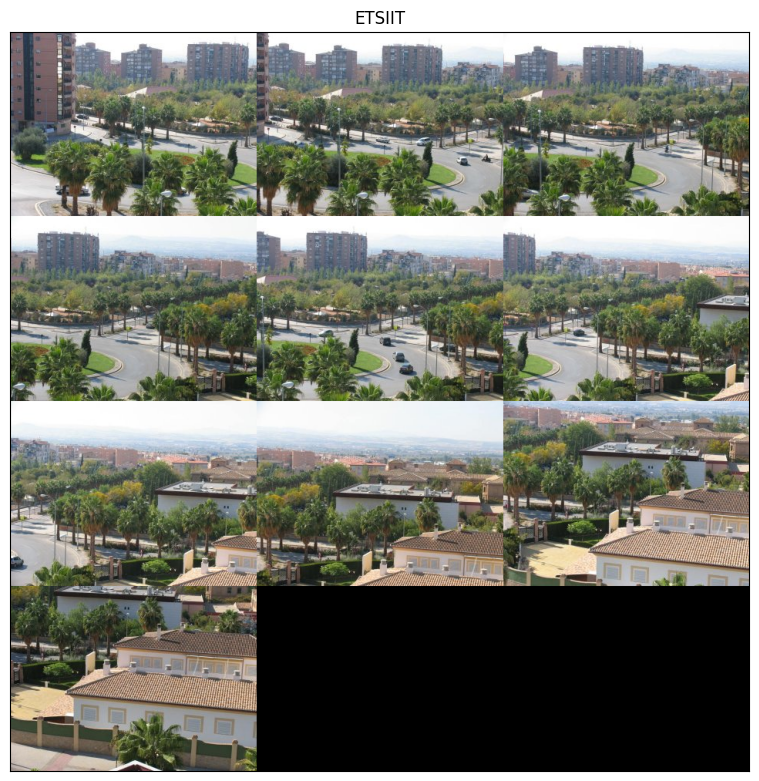

In [ ]:
displayMI_ES(images, title='ETSIIT',factor=2)

En este caso, vemos que las primeras 6 imágenes son bastante similares y las últimas 4 también lo son. Parece buena opción quedarse con la imagen número 6 ( 5 en el vector ) como centro. Necesitamos crear un canvas con **setCanvas** en el que podamos colocar el mosaico. Para ello tomamos las dimensiones de altura máxima y la suma del ancho ( ya que parece razonable que el mosaico tenga un altura parecida a la imagen más alta y un ancho de la suma del ancho de las imágenes ). Se toman finalmente las dimensiones
2,3 * suma_ancho  y 2,3 * max_alto tras varios experimentos. Podría haber puesto una batería de dimensiones y mostrar resultados hasta escoger un tamaño adecuado pero en mi opinión sumaría al notebook mucha información que creo que no aporta mayor valor en cuanto a mostrar mi conocimiento sobre el tema más allá de ver que el panorama cabe en el canvas. Se ha escogido el primer valor donde cabe justamente el mosaico tanto por alto como por ancho.

In [ ]:
centro = 5

# Calculamos la maxima altura del vector de imagenes y la suma del ancho
ancho_im = np.sum([im.shape[1] for im in images])
alto_im = np.max([im.shape[0] for im in images])

# Tomamos el coeficiente 2.3 por estas dimensiones tras hacer varios experimentos
h_mosaic = int(2.3 * alto_im)
w_mosaic = int(2.3 * ancho_im)
mosaic = setCanvas(h_mosaic,w_mosaic,3)

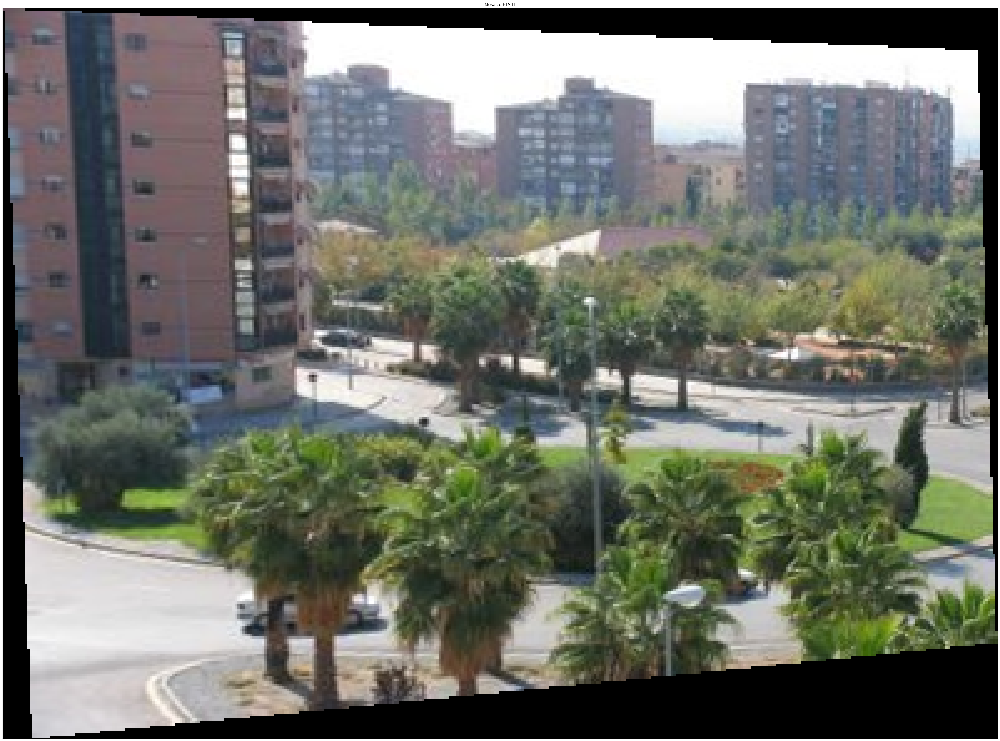

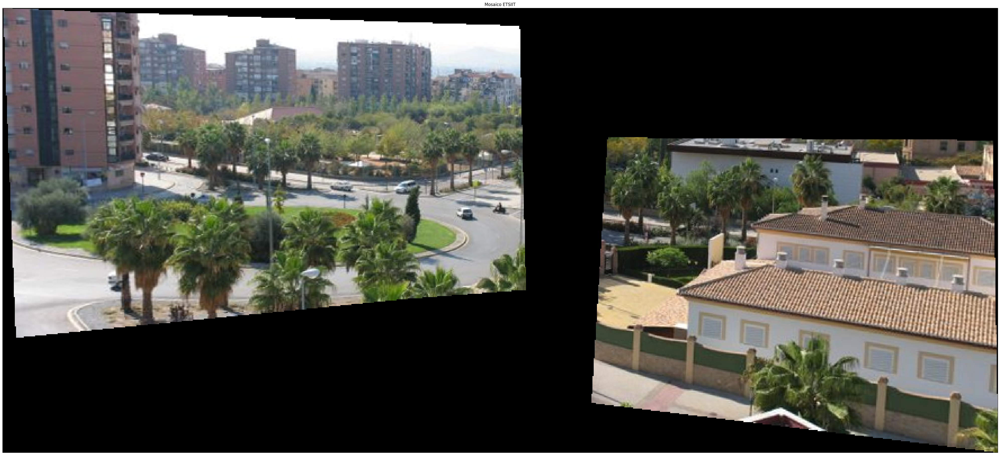

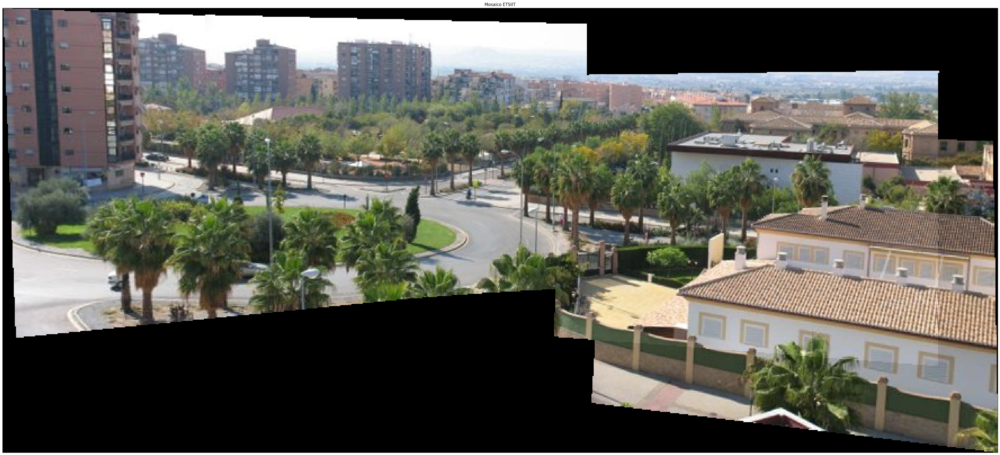

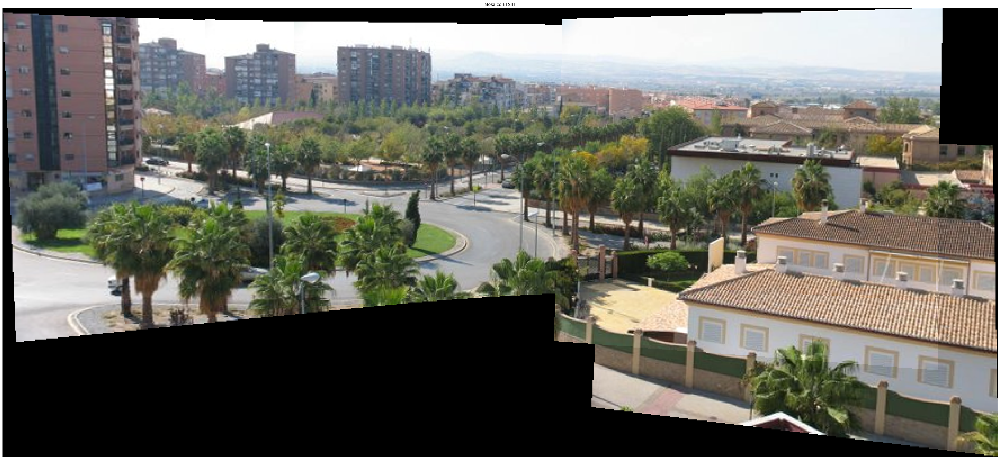

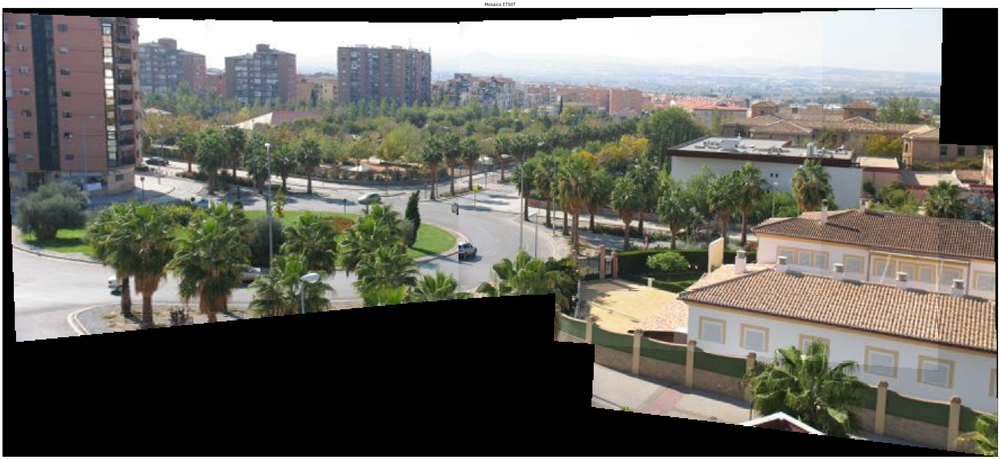

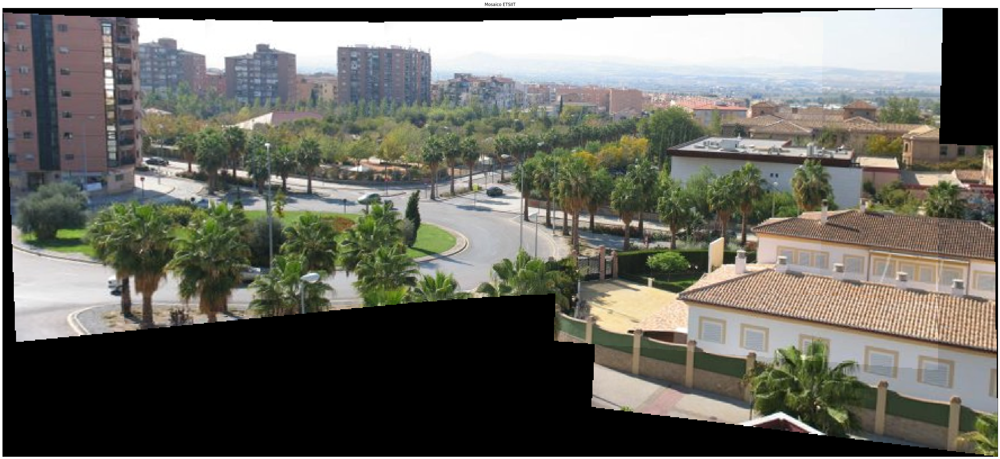

In [ ]:


# Calculamos las homografías para pasar cada imagen a la siguiente
H = computeLocalHomographies(images,method='KNN', Ransac_Error=5.0,Min_Match_Count=25)

# Calculamos las operaciones para llevar al centro
H_mosaic = mosaicHomographies(H,centro)

# Calculamos la operacion de traslacion al canvas
H0 = axesHomography(images[centro].shape,mosaic.shape)

# Llevamos las imagenes al canvas
mosaic = composeMosaic(images,mosaic,H_mosaic,centro,H0)

# A CUBRIR POR EL ALUMNADO
displayIm(blackOut(mosaic),'Mosaico ETSIIT',8)


Como se puese observar, tenemos construído el panorama de forma bastante coherente, por lo que parece que tanto la detección de keypoints, como el algoritmo de matching, como la detección de homografías y el traslado al canvas se han hecho de forma correcta. Además, la evolución del canvas es coherente. Como vemos, al principio se pega la imagen más alejada del centro (**recordemos que el centro es la imagen de índice 5**) como es la **imagen 0**. Después tenemos otras cuatro iteraciones correspondientes a las imágenes a distancia 4 del centro, es decir **imágenes 1-9** después **imágenes 2-8** , **3-7 , 4-6** y por último el centro, lo que hacen 6 evoluciones. Para concluir con el ejemplo, vamos a usar **cv2.Stitcher()** para crear un panorama y comparar resultados.

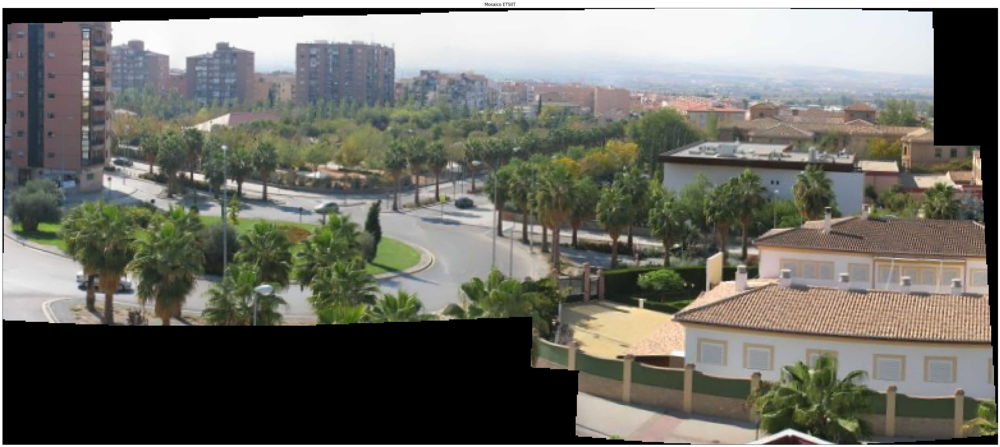

In [ ]:

# Creamos el objeto stitcher
stitcher = cv2.Stitcher_create(cv2.Stitcher_PANORAMA)

# Calculamos el panorama en base a nuestro vector de imagenes
status, panorama = stitcher.stitch(images)

if status == cv2.Stitcher_OK:
  displayIm(blackOut(panorama),'Mosaico ETSIIT',8)

Como podemos observar, el resultado es bastante parecido. En cambio, en nuestro caso quizá se aprecia algo más de calidad de imagen en nuestra implementación manual. De nuevo esto parece indicar que el resultado es correcto por la similitud con la función de openCV.

## <font color='blue'> Mosaico Corridor

In [ ]:
images=[]
PREFIX='corridor/'
nameImages=['Picture1.jpg','Picture2.jpg','Picture3.jpg','Picture4.jpg','Picture5.jpg','Picture6.jpg','Picture7.jpg','Picture8.jpg']
for item in nameImages:
   images.append(readIm(get_image(PREFIX+item),flagColor=1))

Vamos ahora a repetir el proceso con este conjunto de imágenes. Se van a visualizar para seleccionar el centro.

In [ ]:
for im in images:
  print(im.shape)


(161, 214, 3)
(161, 214, 3)
(334, 446, 3)
(161, 214, 3)
(161, 214, 3)
(335, 446, 3)
(161, 214, 3)
(161, 214, 3)


Como podemos observar, estas imágenes son de dimensiones diferentes, luego no podemos usar **displayMI_ES** como en la anterior opción y se visualizarán una a una.

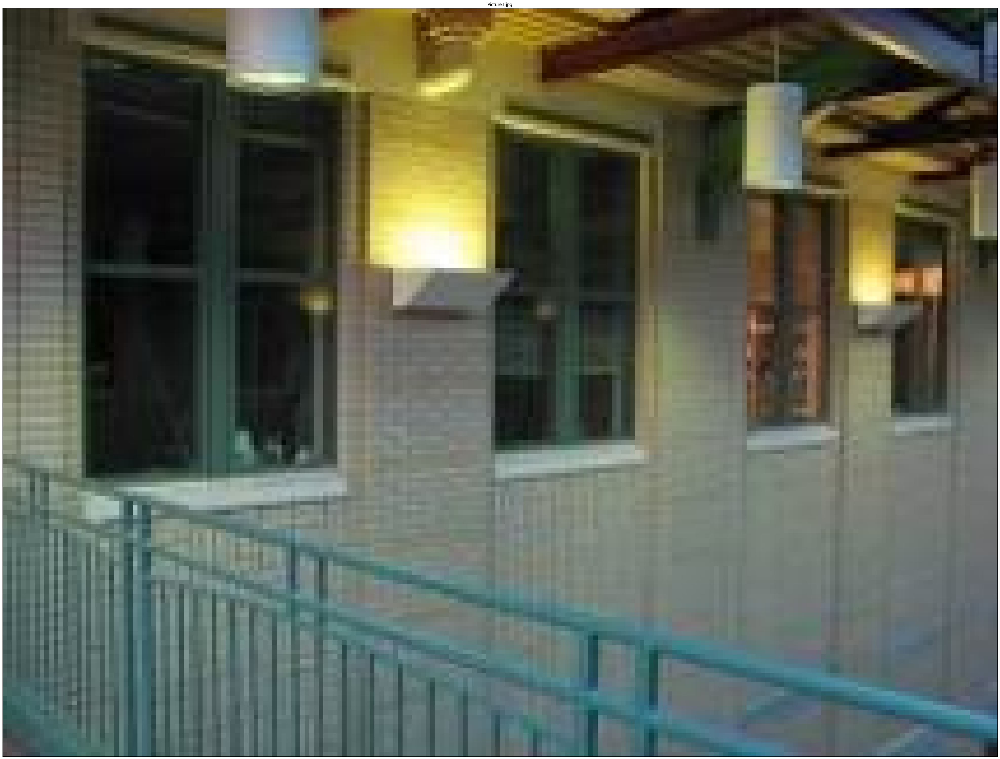

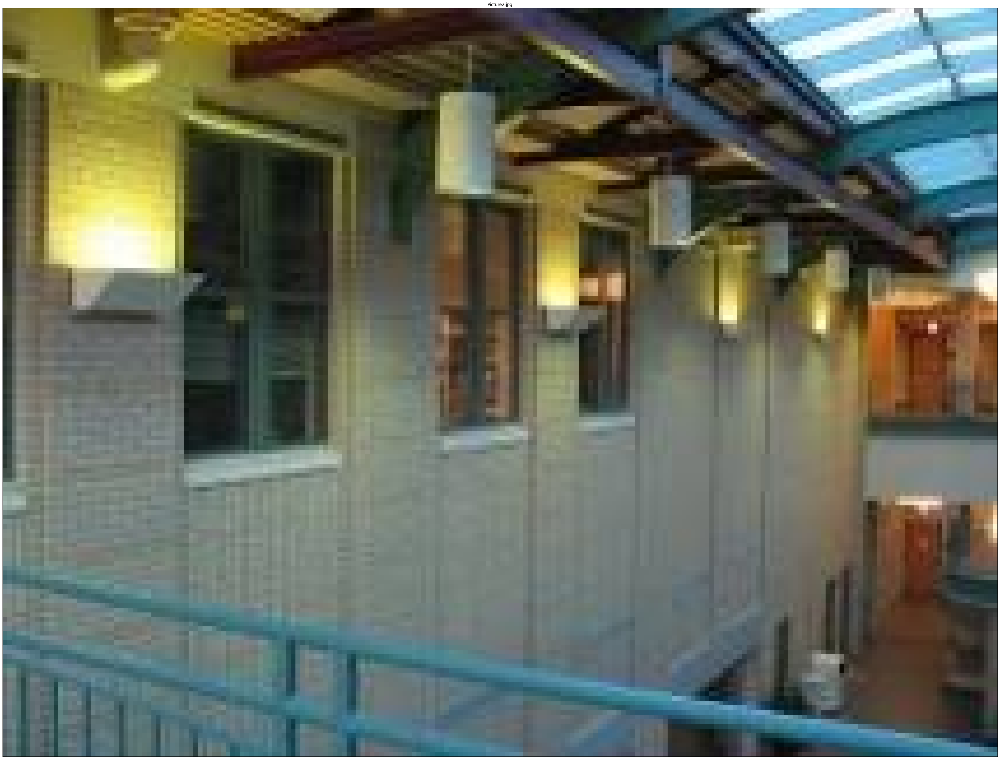

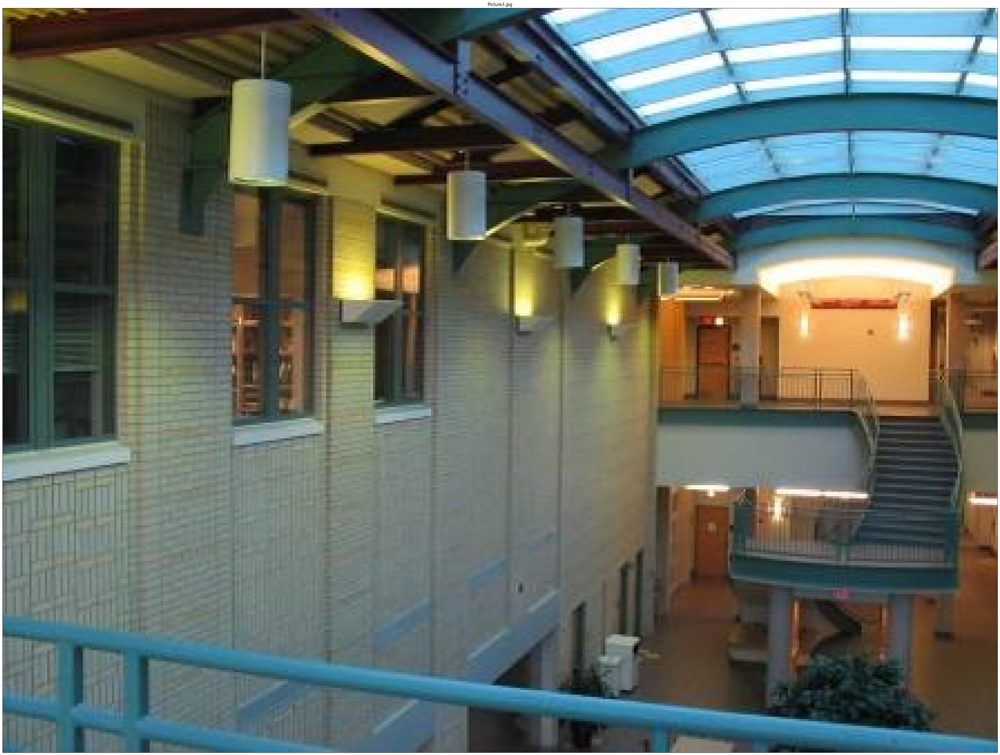

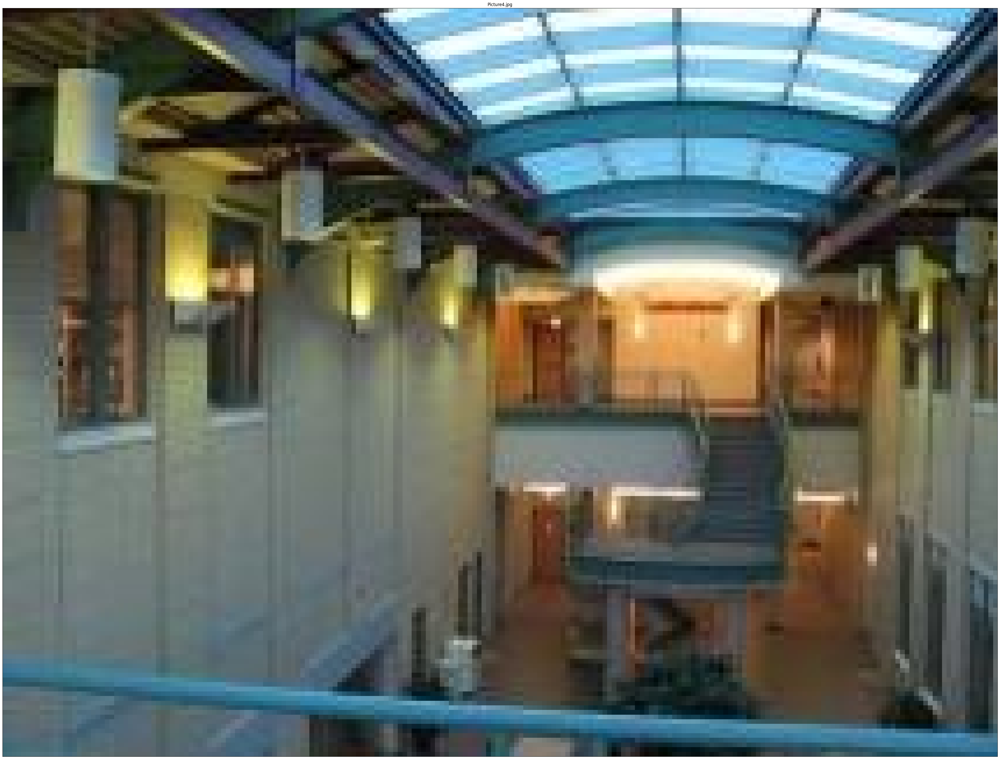

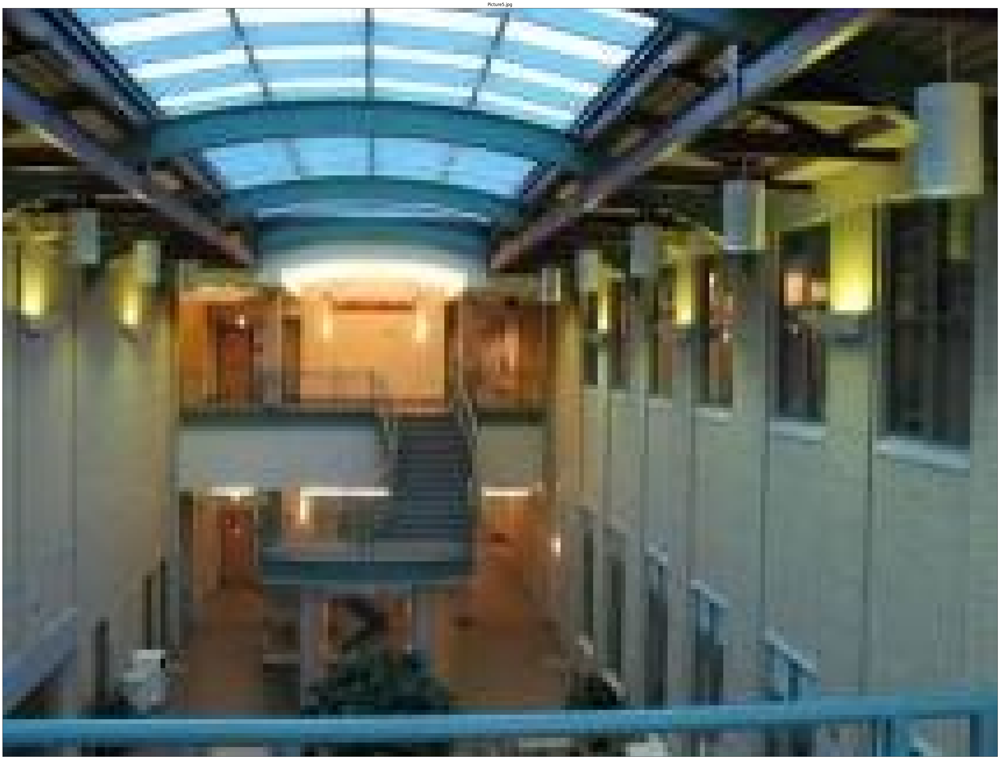

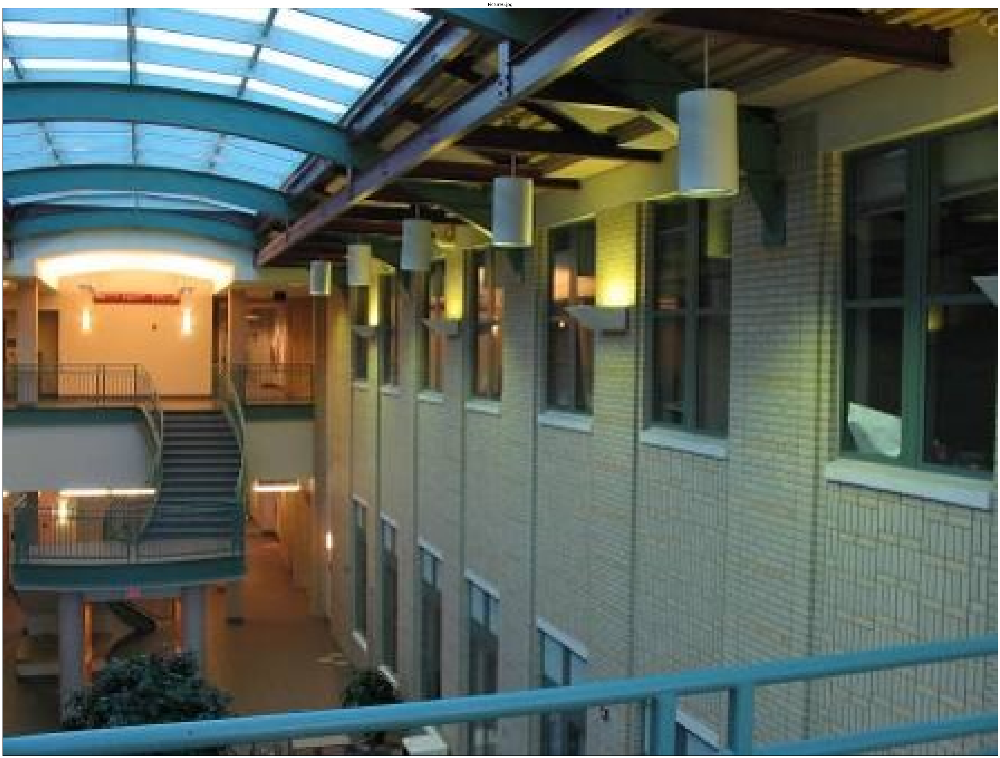

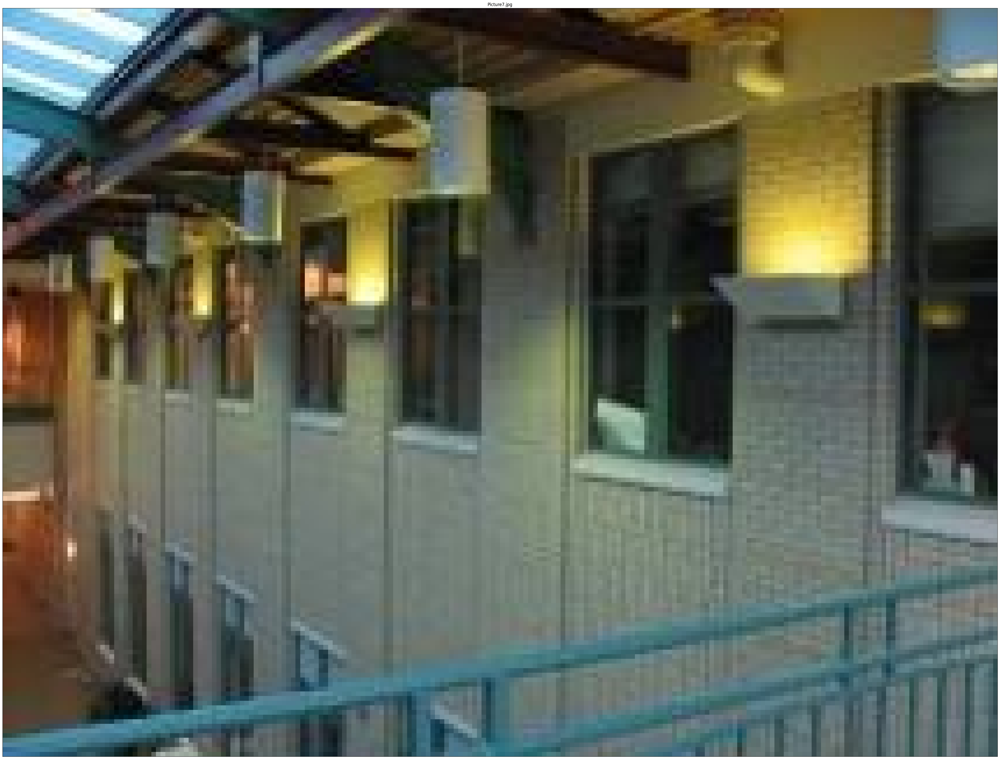

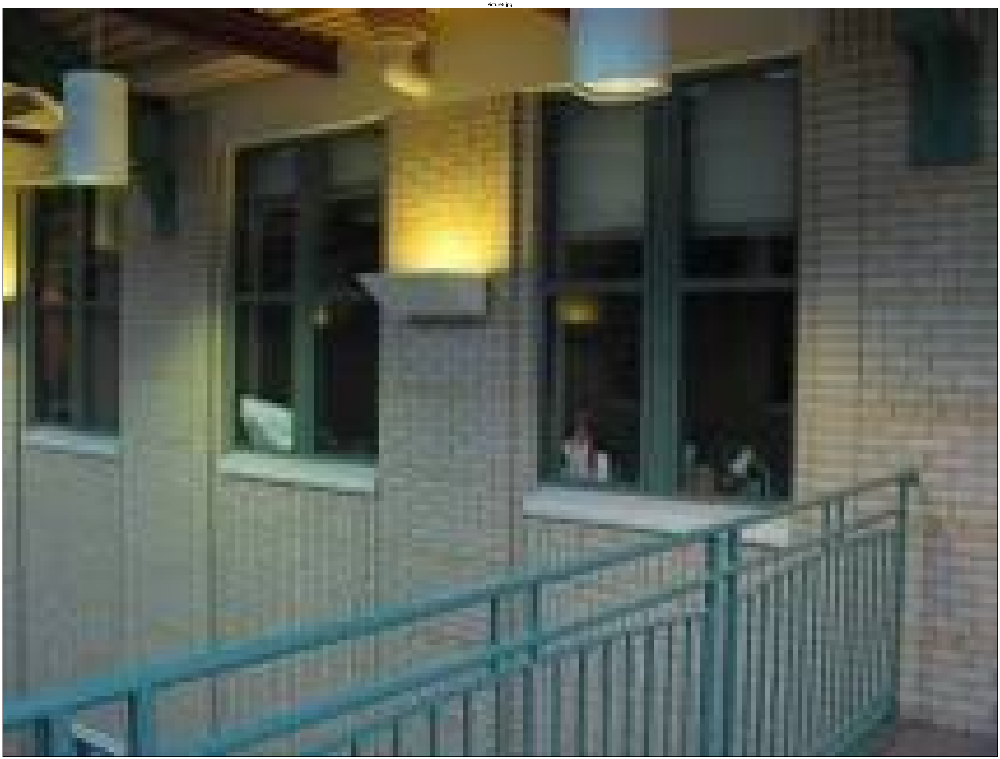

In [ ]:
for im, name in zip(images,nameImages):
  displayIm(im,name,8)

Como vemos, las imágenes parecen estar ordenadas y la imagen número 4 ( índice 3 ) parece definir un buen centro para el panorama al contener la parte entre los dos edificios. Para las dimensiones del canvas se opera similar al aparato anterior, tomando la suma del ancho de las imágenes y el máximo del alto de las imágenes como medida aproximada del canvas. Después se selecciona un coeficiente para multiplicar ambas dimensiones hasta obtener un canvas donde nuestro mosaico esté contenido. Del mismo modo que en el apartado anterior, no se van a hacer pruebas con diferentes tamaños para no saturar el notebook y tomamos 1.3 como coeficiente que se ajusta bien a nuestras necesidades ( encontrado tras una serie de experimentos ).

In [ ]:
centro = 3
# Calculamos el max_H y la suma del ancho de las imagenes
ancho_im = np.sum([im.shape[1] for im in images])
alto_im = np.max([im.shape[0] for im in images])

# Construimos el canvas sobre el que posicionar el mosaico
h_mosaic = int(1.3 * alto_im)
w_mosaic = int(1.3 * ancho_im)
mosaic = setCanvas(h_mosaic,w_mosaic,3)

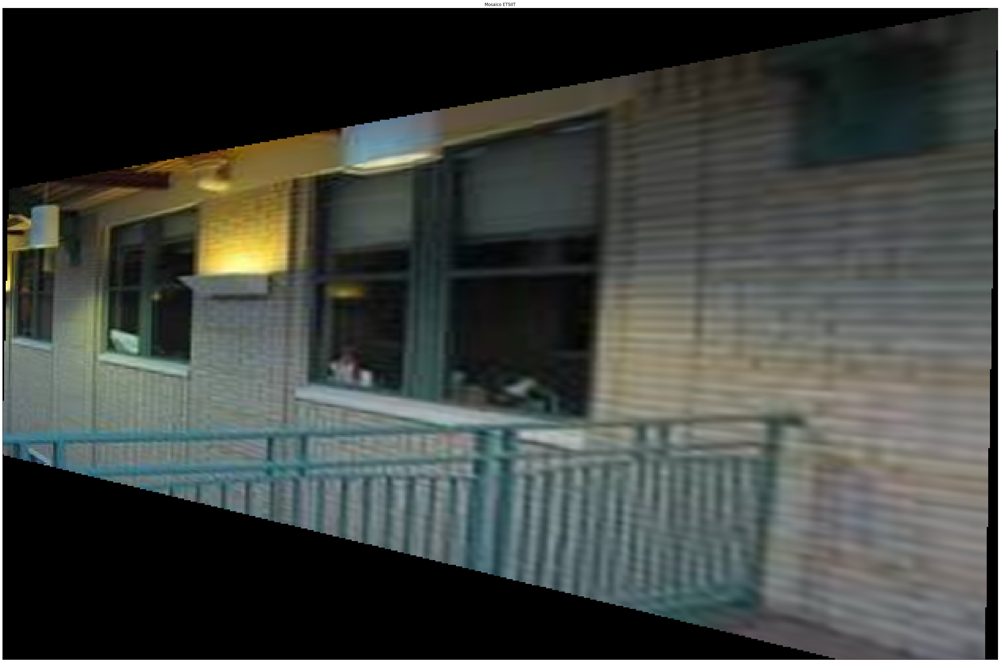

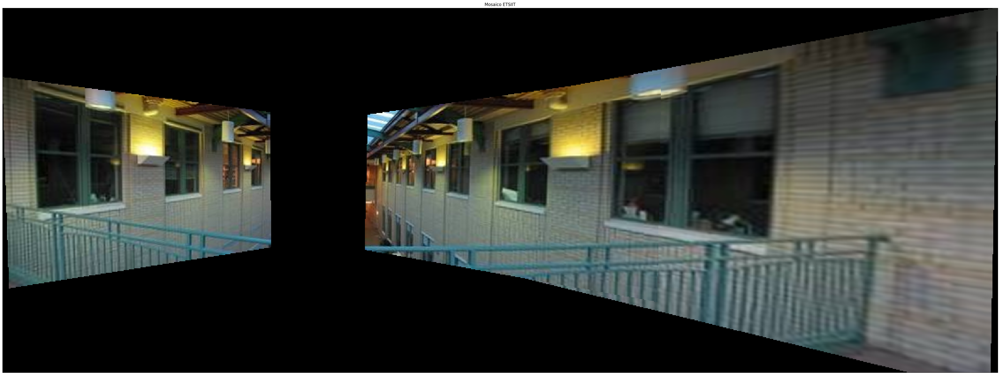

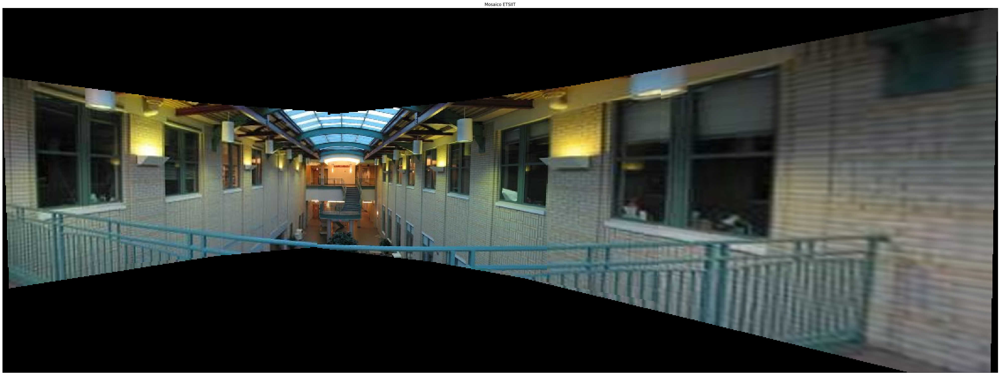

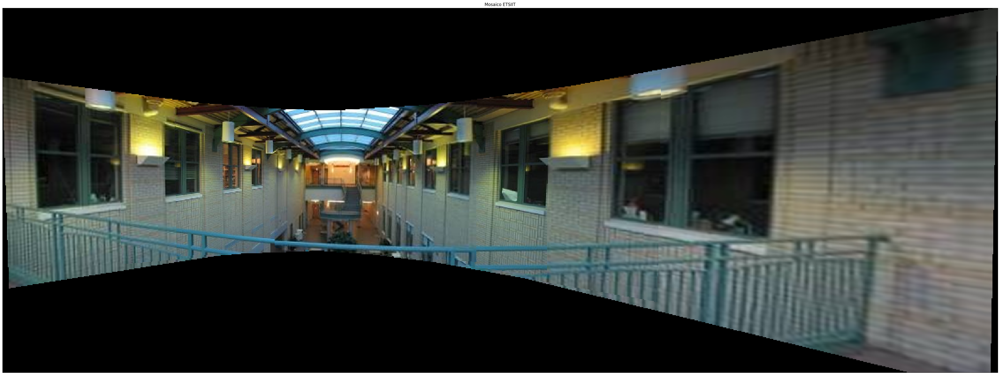

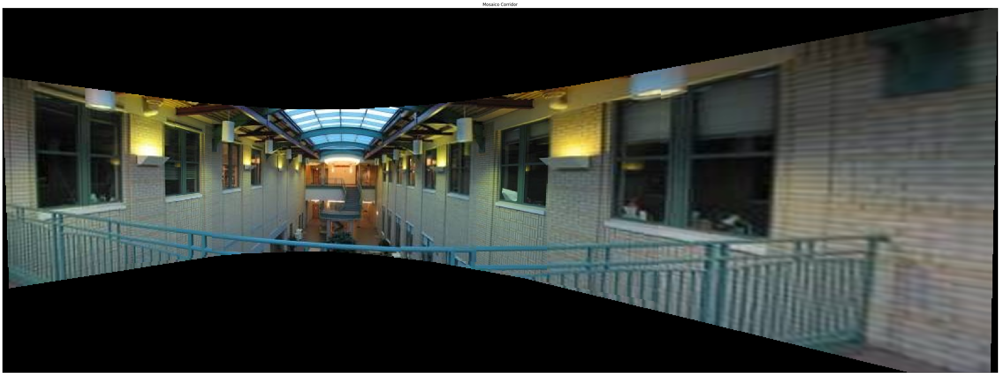

In [ ]:
# Calculamos las homografías para pasar cada imagen a la siguiente
H = computeLocalHomographies(images,method='KNN', Ransac_Error=5.0,Min_Match_Count=25)

# Calculamos las operaciones para llevar al centro
H_mosaic = mosaicHomographies(H,centro)

# Calculamos la operacion de traslacion al canvas
H0 = axesHomography(images[centro].shape,mosaic.shape)

# Llevamos las imagenes al canvas
mosaic = composeMosaic(images,mosaic,H_mosaic,centro,H0)


# A CUBRIR POR EL ALUMNADO
displayIm(blackOut(mosaic),'Mosaico Corridor',8)

Como podemos comprobar, tenemos un panorama que vuelve a mostrar un resultado bastante coherente a nivel visual. Además, si nos fijamos en la evolución podemos ver el mismo patrón que en el apartado anterior donde:
*   **ev1** ->  imagen 7 con dist(im_7) = 4
*   **ev2** ->  imágenes 0,6  con dist(im_6,im_0) = 3
*   **ev3** ->  imágenes 1,5  con dist(im_1,im_5) = 2
*   **ev4** ->  imágenes 2,4  con dist(im_2,im_4) = 1
*   **ev5** ->  imagen 3 (centro) con dist(centro) = 0

De nuevo, vamos a comparar el resultado con el panorama proporcionado por openCV.

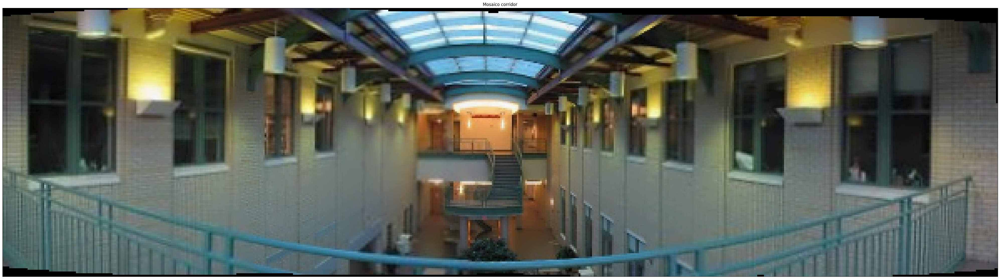

In [ ]:
# Creamos el objeto stitcher
stitcher = cv2.Stitcher_create(cv2.Stitcher_PANORAMA)

# Calculamos el panorama en base a nuestro vector de imagenes
status, panorama = stitcher.stitch(images)

if status == cv2.Stitcher_OK:
  displayIm(blackOut(panorama),'Mosaico corridor',8)

En este caso, sí que apreciamos una clara diferencia en el resultado, donde el proporcionado por openCV es más limpio. Esto se puede deber quizá a la diferencia en el tamaño de las imágenes ya que, en el apartado anterior, teníamos imágenes de mismo tamaño ( como corrobora el uso de displayMI_ES sin errores ) y el resultado era muy parecido al que proporciona openCV. Como experimento, vamos a redimensionar las imágenes al mismo tamaño para comprobar qué obtenemos.

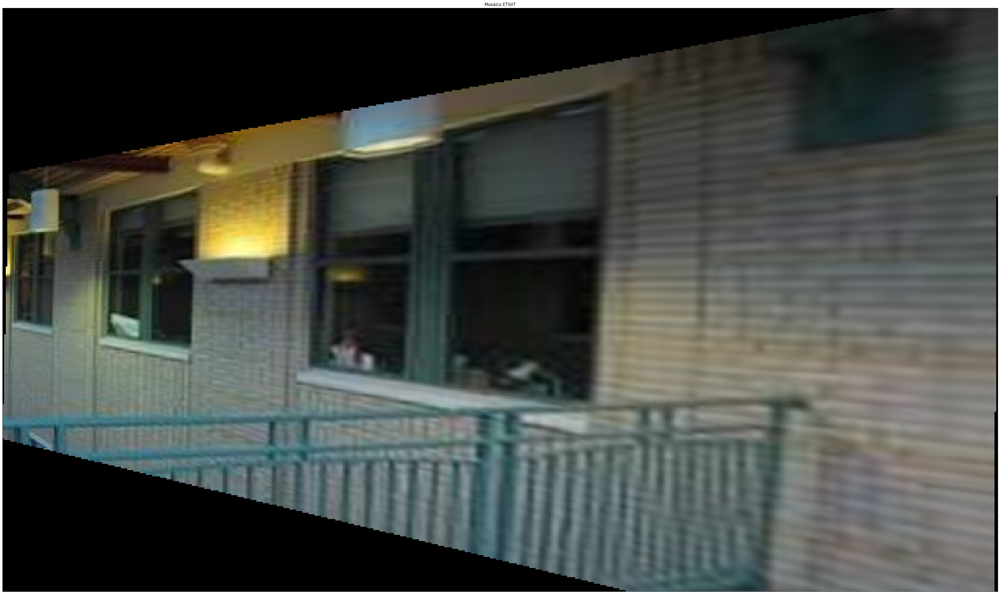

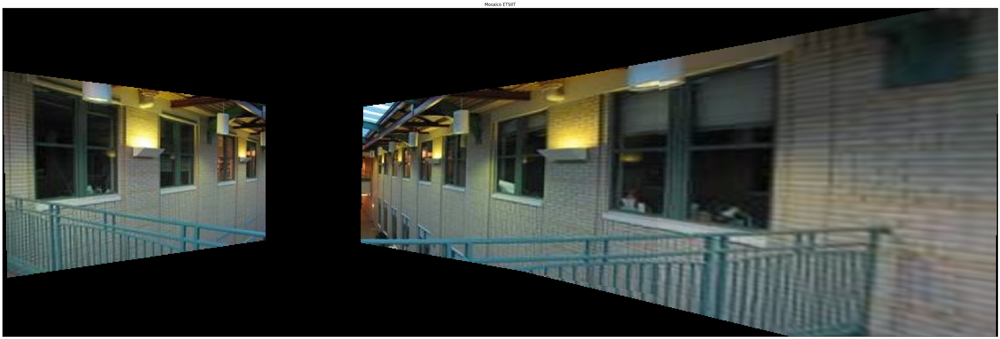

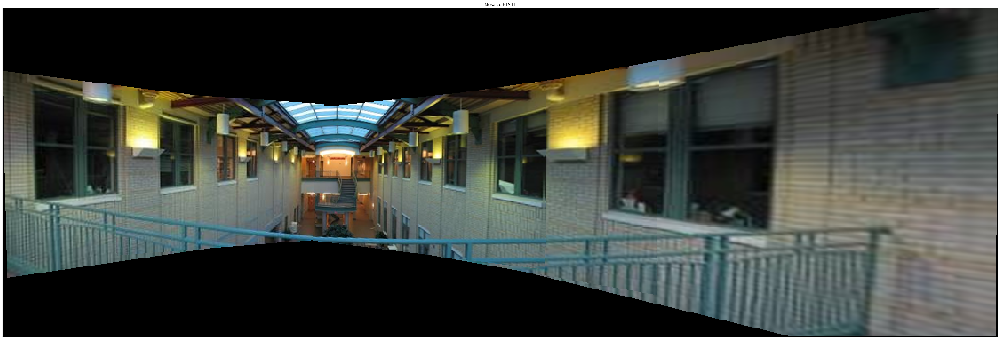

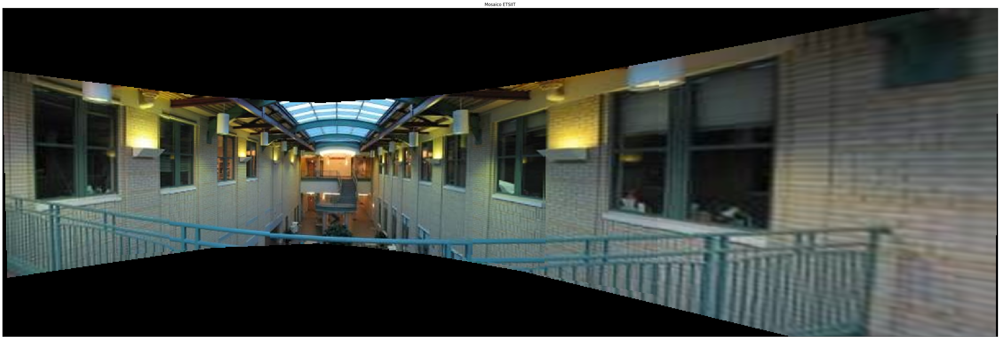

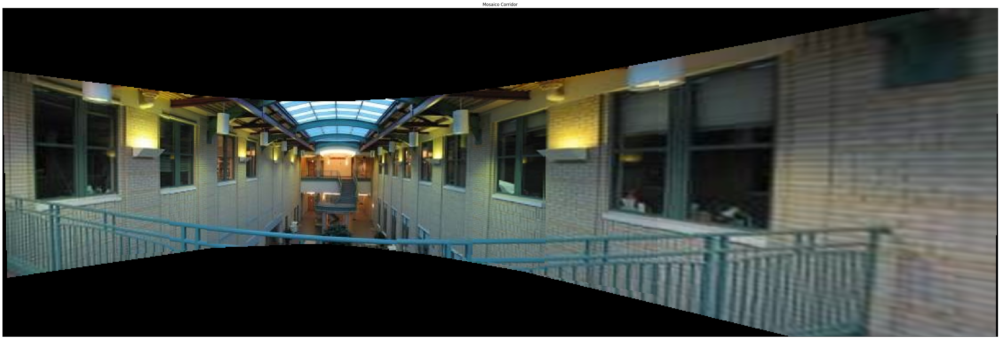

In [ ]:
images_resize =  [cv2.resize(im, (images[0].shape[1],images[0].shape[0])) for im in images]

centro = 3
# Calculamos el max_H y la suma del ancho de las imagenes
ancho_im = np.sum([im.shape[1] for im in images_resize])
alto_im = np.max([im.shape[0] for im in images_resize])

# Construimos el canvas sobre el que posicionar el mosaico
h_mosaic = int(2.3 * alto_im)
w_mosaic = int(2.3 * ancho_im)
mosaic = setCanvas(h_mosaic,w_mosaic,3)

# Calculamos las homografías para pasar cada imagen a la siguiente
H = computeLocalHomographies(images_resize,method='KNN', Ransac_Error=5.0,Min_Match_Count=25)

# Calculamos las operaciones para llevar al centro
H_mosaic = mosaicHomographies(H,centro)

# Calculamos la operacion de traslacion al canvas
H0 = axesHomography(images_resize[centro].shape,mosaic.shape)

# Llevamos las imagenes al canvas
mosaic = composeMosaic(images_resize,mosaic,H_mosaic,centro,H0)


# A CUBRIR POR EL ALUMNADO
displayIm(blackOut(mosaic),'Mosaico Corridor',8)

Como podemos comprobar, el resultado sigue sin ser el mismo. Tras consultar https://docs.opencv.org/4.x/d1/d46/group__stitching.html, podemos ver que el pipeline que usa openCV en su stitcher, implica más cosas que nuestro pipeline que era: detectar kp y features -> hacer matching -> calcular homografías y operaciones para llevar al canvas -> dibujar mosaico. En el caso de openCV se puede comprobar como el pipeline es mucho mayor donde incluyen elementos como estimación de los parámetros de cámara o diferentes modos de warp como puede ser el cilíndrico o esférico, lo que puede causar que en nuestro caso veamos el panorama curvado en lugar de plano que es como lo realiza openCV.

Como conclusión final, parece que es más complicado generar un panorama de calidad en el último caso, pues vemos que nuestro panorama se curva hacia el centro dando lugar a una apariencia extraña donde openCV utiliza herramientas para corregir este problema y generar un panorama que de la sensación de ser plano.